# Benchmark Results

This notebook reproduces the benchmark figures from the paper.
It compares three RL algorithms (**PPO**, **SAC**, **TD3**) and a set of
planning baselines (**FiPla**, **Constant**, **Random**, **Shading**, **MPC** variants)
on the `survival-second-price-exponential` scenario over **1 000 seeds**.

## How to run this notebook

The notebook reads pre-computed per-step CSVs from `benchmark/benchmark_results/`.
To generate them from scratch:

1. Train the RL agents (`benchmark/train_rl.py`) and the MLP valuation head (`benchmark/train_mlp.py`).
2. Run the evaluation script (`benchmark/evaluate.py`) to produce the CSVs.
3. Adapt the paths and names of the csv files in the cells below depending on the saving paths and names you chose. 

See [`BENCHMARK.md`](BENCHMARK.md) for the full protocol, training commands, hyperparameters,
pretrained model layout, and evaluation steps.

Pre-generated figures are available in [`../figures/`](../figures/) and can be viewed without running anything.

In [1]:
import sys, pathlib
# Notebook lives in benchmark/; add repo root so `benchmark.*` imports resolve
repo_root = pathlib.Path().resolve().parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
%matplotlib inline
from benchmark.evaluate import score_matrix
from benchmark import plots
import pandas as pd
import glob
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns

## Constant bid sweep

Grid search over the fixed bid value b for `ConstantPolicy` (η = 50). Each bid is evaluated over 30 seeds; we report mean ± std of total episode reward and the per-seed distribution. Use this to calibrate the `--constant-bid` argument passed to `evaluate.py`.

Results are split by squashing function (**clip** vs **sigmoid**).

To generate the CSVs:
```bash
# Clip
python benchmark/tune_constant_bid.py --horizon-eta 50 --n-bids 30 --bid-min 0.0 --bid-max 5.0
python benchmark/tune_constant_bid.py --horizon-eta 50 --n-bids 20 --bid-min 0.0 --bid-max 1.0

# Sigmoid
python benchmark/tune_constant_bid.py --horizon-eta 50 --squashing sigmoid --n-bids 30 --bid-min 0.0 --bid-max 5.0
python benchmark/tune_constant_bid.py --horizon-eta 50 --squashing sigmoid --n-bids 20 --bid-min 0.0 --bid-max 1.0
```

### Clip

In [3]:
# Auto-pick the most recent constant-bid sweep CSVs (clip, η=50)
_pattern_gross = "benchmark_results/clip_results/constant_sweeps/survival-second-price-exponential_eta50_constant_bid_sweep_gross*.csv"
_pattern_refined = "benchmark_results/clip_results/constant_sweeps/survival-second-price-exponential_eta50_constant_bid_sweep_refined*.csv"
_files_gross = sorted(glob.glob(_pattern_gross))
_files_refined = sorted(glob.glob(_pattern_refined))
if not _files_gross:
    raise FileNotFoundError(
        f"No constant-bid sweep CSV found matching {_pattern_gross!r}.\n"
        "Run:  python benchmark/tune_constant_bid.py --horizon-eta 50"
    )
if not _files_refined:
    raise FileNotFoundError(
        f"No constant-bid sweep CSV found matching {_pattern_refined!r}.\n"
        "Run:  python benchmark/tune_constant_bid.py --horizon-eta 50"
    )

constant_gross_df = pd.read_csv(_files_gross[-1])
constant_refined_df = pd.read_csv(_files_refined[-1])
print(f"Loaded: {_files_gross[-1]}")
print(f"Loaded: {_files_refined[-1]}")

constant_gross_summary = (
    constant_gross_df.sort_values(["bid_value", "seed", "step"])
    .groupby(["bid_value", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)
constant_refined_summary = (
    constant_refined_df.sort_values(["bid_value", "seed", "step"])
    .groupby(["bid_value", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)

Loaded: benchmark_results/clip_results/constant_sweeps/survival-second-price-exponential_eta50_constant_bid_sweep_gross_2026-05-05_14-36-19.csv
Loaded: benchmark_results/clip_results/constant_sweeps/survival-second-price-exponential_eta50_constant_bid_sweep_refined_2026-05-05_14-38-18.csv


#### Results for $\eta = 50$

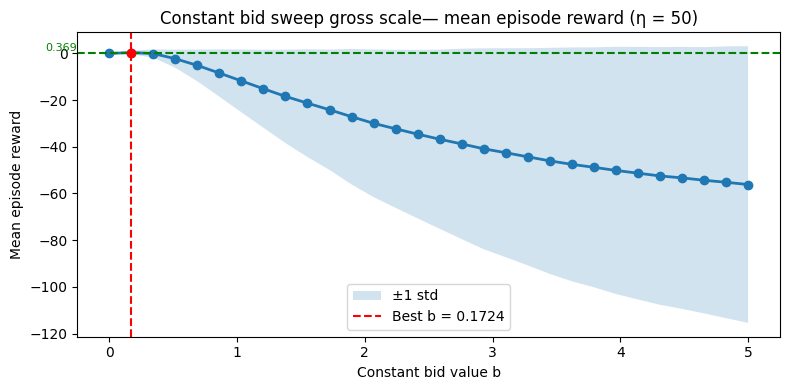

Best b = 0.1724  (mean reward = 0.3690)


In [4]:

mean_r   = constant_gross_summary.groupby("bid_value")["episode_reward"].mean()
std_r    = constant_gross_summary.groupby("bid_value")["episode_reward"].std()
best_bid_gross = mean_r.idxmax()
best_reward_gross = mean_r.loc[best_bid_gross]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.scatter(best_bid_gross, best_reward_gross, color="red", zorder=5)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axhline(best_reward_gross, color="green", linestyle="--")
ax.text(
    ax.get_xlim()[0],
    best_reward_gross,
    f"{best_reward_gross:.3f}",
    va="bottom",
    ha="right",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axvline(best_bid_gross, color="red", linestyle="--", label=f"Best b = {best_bid_gross:.4g}")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Mean episode reward")
ax.set_title("Constant bid sweep gross scale— mean episode reward (η = 50)")
ax.legend()
plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/constant_bid_sweep_gross_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best b = {best_bid_gross:.4g}  (mean reward = {best_reward_gross:.4f})")

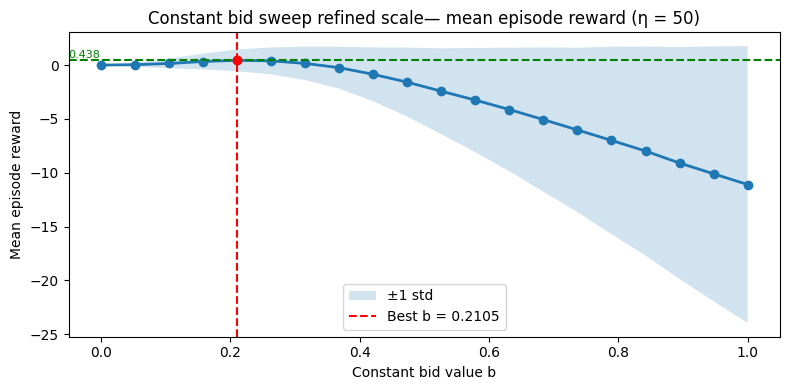

Best b = 0.2105  (mean reward = 0.4379)


In [5]:
mean_r   = constant_refined_summary.groupby("bid_value")["episode_reward"].mean()
std_r    = constant_refined_summary.groupby("bid_value")["episode_reward"].std()
best_bid_refined = mean_r.idxmax()
best_reward_refined = mean_r.loc[best_bid_refined]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.scatter(best_bid_refined, best_reward_refined, color="red", zorder=5)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_bid_refined, color="red", linestyle="--", label=f"Best b = {best_bid_refined:.4g}")
ax.text(
    ax.get_xlim()[0],
    best_reward_refined,
    f"{best_reward_refined:.3f}",
    va="bottom",
    ha="left",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axhline(best_reward_refined, color="green", linestyle="--")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Mean episode reward")
ax.set_title("Constant bid sweep refined scale— mean episode reward (η = 50)")
ax.legend()
plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/constant_bid_sweep_refined_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best b = {best_bid_refined:.4g}  (mean reward = {best_reward_refined:.4f})")

/tmp/ipykernel_355218/157400307.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{b:.2f}" for b in bids_sorted], rotation=45, ha="right")


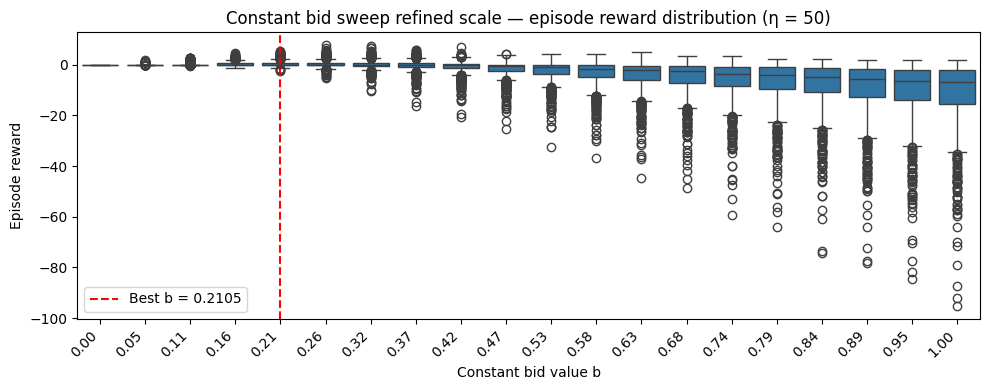

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
bids_sorted = sorted(constant_refined_summary["bid_value"].unique())
sns.boxplot(
    data=constant_refined_summary, x="bid_value", y="episode_reward",
    order=bids_sorted,
    ax=ax,
)
ax.set_xticklabels([f"{b:.2f}" for b in bids_sorted], rotation=45, ha="right")
ax.axvline(bids_sorted.index(best_bid_refined), color="red", linestyle="--", label=f"Best b = {best_bid_refined:.4g}")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Episode reward")
ax.set_title("Constant bid sweep refined scale — episode reward distribution (η = 50)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/constant_bid_sweep_dist_eta50.pdf", bbox_inches="tight")
plt.show()

#### Results for $\eta = 100$

In [7]:

# Auto-pick the most recent constant-bid sweep CSVs (clip, η=100)
_pattern_gross_eta100 = "benchmark_results/clip_results/constant_sweeps/survival-second-price-exponential_eta100_constant_bid_sweep_gross*.csv"
_pattern_refined_eta100 = "benchmark_results/clip_results/constant_sweeps/survival-second-price-exponential_eta100_constant_bid_sweep_refined*.csv"
_files_gross = sorted(glob.glob(_pattern_gross_eta100))
_files_refined = sorted(glob.glob(_pattern_refined_eta100))
if not _files_gross:
    raise FileNotFoundError(
        f"No constant-bid sweep CSV found matching {_pattern_gross_eta100!r}.\n"
        "Run:  python benchmark/tune_constant_bid.py --horizon-eta 100"
    )
if not _files_refined:
    raise FileNotFoundError(
        f"No constant-bid sweep CSV found matching {_pattern_refined_eta100!r}.\n"
        "Run:  python benchmark/tune_constant_bid.py --horizon-eta 100"
    )

constant_gross_df_eta100 = pd.read_csv(_files_gross[-1])
constant_refined_df_eta100 = pd.read_csv(_files_refined[-1])
print(f"Loaded: {_files_gross[-1]}")
print(f"Loaded: {_files_refined[-1]}")

constant_gross_summary_eta100 = (
    constant_gross_df_eta100.sort_values(["bid_value", "seed", "step"])
    .groupby(["bid_value", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)
constant_refined_summary_eta100 = (
    constant_refined_df_eta100.sort_values(["bid_value", "seed", "step"])
    .groupby(["bid_value", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)

Loaded: benchmark_results/clip_results/constant_sweeps/survival-second-price-exponential_eta100_constant_bid_sweep_gross_2026-05-06_17-56-32.csv
Loaded: benchmark_results/clip_results/constant_sweeps/survival-second-price-exponential_eta100_constant_bid_sweep_refined_2026-05-06_17-51-41.csv


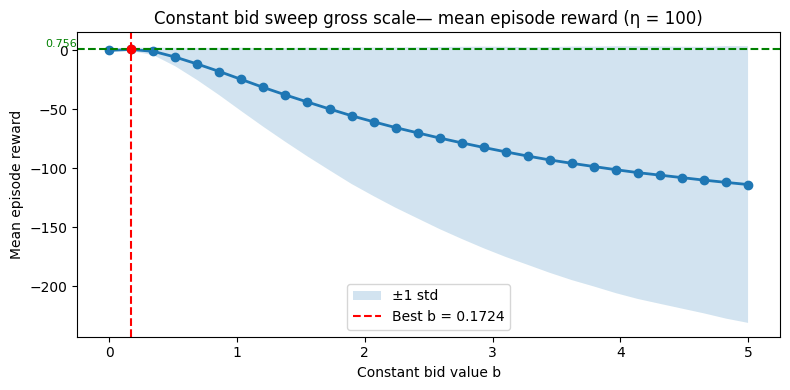

Best b = 0.1724  (mean reward = 0.7560)


In [8]:
mean_r   = constant_gross_summary_eta100.groupby("bid_value")["episode_reward"].mean()
std_r    = constant_gross_summary_eta100.groupby("bid_value")["episode_reward"].std()
best_bid_gross_eta100 = mean_r.idxmax()
best_reward_gross_eta100 = mean_r.loc[best_bid_gross_eta100]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.scatter(best_bid_gross_eta100, best_reward_gross_eta100, color="red", zorder=5)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axhline(best_reward_gross_eta100, color="green", linestyle="--")
ax.text(
    ax.get_xlim()[0],
    best_reward_gross_eta100,
    f"{best_reward_gross_eta100:.3f}",
    va="bottom",
    ha="right",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axvline(best_bid_gross_eta100, color="red", linestyle="--", label=f"Best b = {best_bid_gross_eta100:.4g}")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Mean episode reward")
ax.set_title("Constant bid sweep gross scale— mean episode reward (η = 100)")
ax.legend()
plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/constant_bid_sweep_gross_mean_eta100.pdf", bbox_inches="tight")
plt.show()
print(f"Best b = {best_bid_gross_eta100:.4g}  (mean reward = {best_reward_gross_eta100:.4f})")

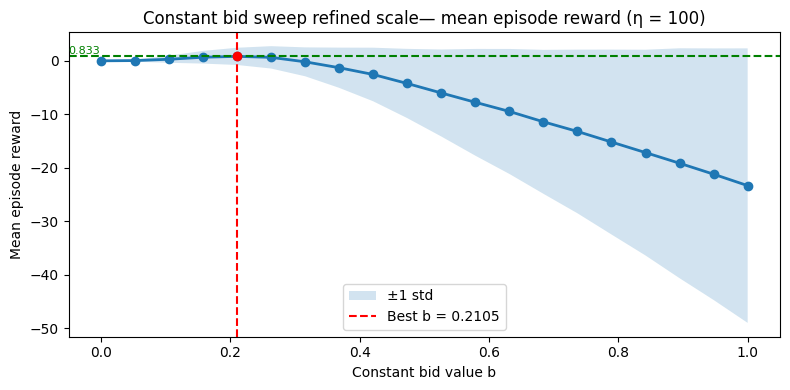

Best b = 0.2105  (mean reward = 0.8333)


In [9]:
mean_r   = constant_refined_summary_eta100.groupby("bid_value")["episode_reward"].mean()
std_r    = constant_refined_summary_eta100.groupby("bid_value")["episode_reward"].std()
best_bid_refined_eta100 = mean_r.idxmax()
best_reward_refined_eta100 = mean_r.loc[best_bid_refined_eta100]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.scatter(best_bid_refined_eta100, best_reward_refined_eta100, color="red", zorder=5)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_bid_refined_eta100, color="red", linestyle="--", label=f"Best b = {best_bid_refined_eta100:.4g}")
ax.text(
    ax.get_xlim()[0],
    best_reward_refined_eta100,
    f"{best_reward_refined_eta100:.3f}",
    va="bottom",
    ha="left",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axhline(best_reward_refined_eta100, color="green", linestyle="--")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Mean episode reward")
ax.set_title("Constant bid sweep refined scale— mean episode reward (η = 100)")
ax.legend()
plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/constant_bid_sweep_refined_mean_eta100.pdf", bbox_inches="tight")
plt.show()
print(f"Best b = {best_bid_refined_eta100:.4g}  (mean reward = {best_reward_refined_eta100:.4f})")

### Sigmoid

#### Results for $\eta = 50$

In [10]:
# Load sigmoid constant-bid sweep CSVs (η=50)
# Gross = wide bid range (max bid > 2.0), refined = narrow range (max bid <= 2.0)
_pattern_sig_cb = "benchmark_results/sigmoid_results/constant-bid/survival-second-price-exponential_eta50_sqsigmoid_constant_bid_sweep*.csv"
_files_sig_cb = sorted(glob.glob(_pattern_sig_cb))
if not _files_sig_cb:
    raise FileNotFoundError(
        f"No sigmoid constant-bid sweep CSV found matching {_pattern_sig_cb!r}.\n"
        "Run:  python benchmark/tune_constant_bid.py --horizon-eta 50 --squashing sigmoid"
    )

_dfs_sig_cb = [(f, pd.read_csv(f)) for f in _files_sig_cb]
_gross_sig  = [(f, df) for f, df in _dfs_sig_cb if df["bid_value"].max() > 2.0]
_refined_sig = [(f, df) for f, df in _dfs_sig_cb if df["bid_value"].max() <= 2.0]

if not _gross_sig:
    raise FileNotFoundError("No sigmoid gross constant-bid CSV found (expected max bid > 2.0).")
if not _refined_sig:
    raise FileNotFoundError("No sigmoid refined constant-bid CSV found (expected max bid <= 2.0).")

constant_sig_gross_df = _gross_sig[-1][1]
constant_sig_refined_df = _refined_sig[-1][1]
print(f"Sigmoid gross:   {_gross_sig[-1][0]}")
print(f"Sigmoid refined: {_refined_sig[-1][0]}")

constant_sig_gross_summary = (
    constant_sig_gross_df.sort_values(["bid_value", "seed", "step"])
    .groupby(["bid_value", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)
constant_sig_refined_summary = (
    constant_sig_refined_df.sort_values(["bid_value", "seed", "step"])
    .groupby(["bid_value", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)

Sigmoid gross:   benchmark_results/sigmoid_results/constant-bid/survival-second-price-exponential_eta50_sqsigmoid_constant_bid_sweep_2026-05-19_11-20-49.csv
Sigmoid refined: benchmark_results/sigmoid_results/constant-bid/survival-second-price-exponential_eta50_sqsigmoid_constant_bid_sweep_2026-05-19_11-22-15.csv


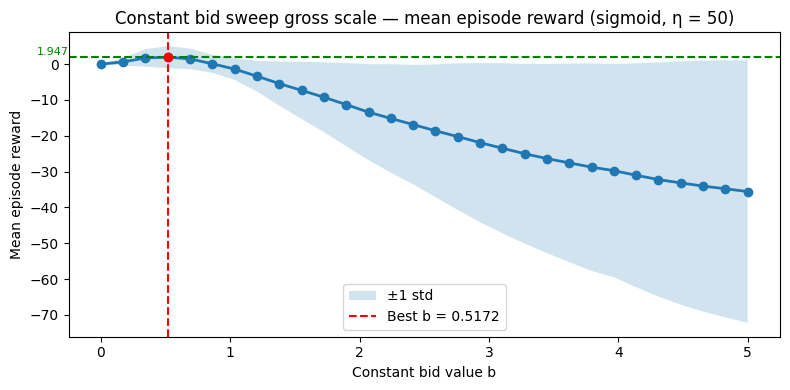

Best b = 0.5172  (mean reward = 1.9468)


In [11]:
mean_r = constant_sig_gross_summary.groupby("bid_value")["episode_reward"].mean()
std_r  = constant_sig_gross_summary.groupby("bid_value")["episode_reward"].std()
best_bid_sig_gross = mean_r.idxmax()
best_reward_sig_gross = mean_r.loc[best_bid_sig_gross]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.scatter(best_bid_sig_gross, best_reward_sig_gross, color="red", zorder=5)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axhline(best_reward_sig_gross, color="green", linestyle="--")
ax.axvline(best_bid_sig_gross, color="red", linestyle="--", label=f"Best b = {best_bid_sig_gross:.4g}")
ax.text(ax.get_xlim()[0], best_reward_sig_gross, f"{best_reward_sig_gross:.3f}",
        va="bottom", ha="right", color="green", fontsize=8)
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Mean episode reward")
ax.set_title("Constant bid sweep gross scale — mean episode reward (sigmoid, η = 50)")
ax.legend()
plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/sigmoid_constant_bid_sweep_gross_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best b = {best_bid_sig_gross:.4g}  (mean reward = {best_reward_sig_gross:.4f})")

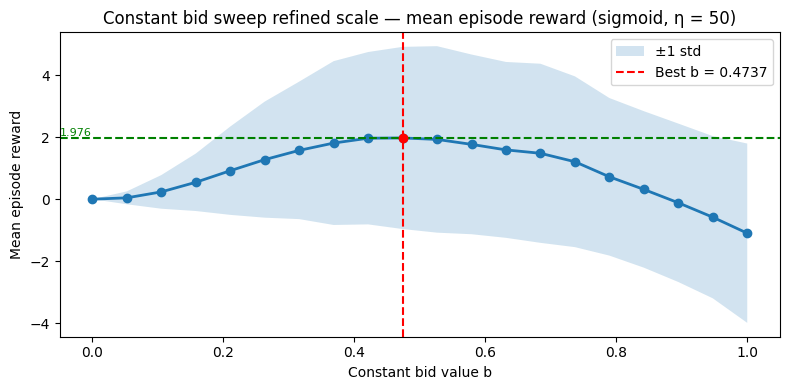

Best b = 0.4737  (mean reward = 1.9760)


In [12]:
mean_r = constant_sig_refined_summary.groupby("bid_value")["episode_reward"].mean()
std_r  = constant_sig_refined_summary.groupby("bid_value")["episode_reward"].std()
best_bid_sig_refined = mean_r.idxmax()
best_reward_sig_refined = mean_r.loc[best_bid_sig_refined]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.scatter(best_bid_sig_refined, best_reward_sig_refined, color="red", zorder=5)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axhline(best_reward_sig_refined, color="green", linestyle="--")
ax.axvline(best_bid_sig_refined, color="red", linestyle="--", label=f"Best b = {best_bid_sig_refined:.4g}")
ax.text(ax.get_xlim()[0], best_reward_sig_refined, f"{best_reward_sig_refined:.3f}",
        va="bottom", ha="left", color="green", fontsize=8)
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Mean episode reward")
ax.set_title("Constant bid sweep refined scale — mean episode reward (sigmoid, η = 50)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/sigmoid_constant_bid_sweep_refined_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best b = {best_bid_sig_refined:.4g}  (mean reward = {best_reward_sig_refined:.4f})")

/tmp/ipykernel_355218/1274017780.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{b:.2f}" for b in bids_sorted_sig], rotation=45, ha="right")


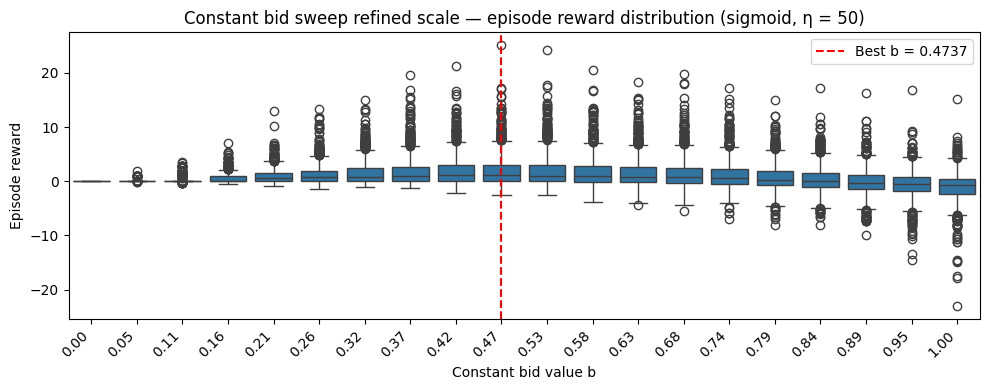

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
bids_sorted_sig = sorted(constant_sig_refined_summary["bid_value"].unique())
sns.boxplot(
    data=constant_sig_refined_summary, x="bid_value", y="episode_reward",
    order=bids_sorted_sig, ax=ax,
)
ax.set_xticklabels([f"{b:.2f}" for b in bids_sorted_sig], rotation=45, ha="right")
ax.axvline(bids_sorted_sig.index(best_bid_sig_refined), color="red", linestyle="--",
           label=f"Best b = {best_bid_sig_refined:.4g}")
ax.set_xlabel("Constant bid value b")
ax.set_ylabel("Episode reward")
ax.set_title("Constant bid sweep refined scale — episode reward distribution (sigmoid, η = 50)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/sigmoid_constant_bid_sweep_dist_eta50.pdf", bbox_inches="tight")
plt.show()

## Shading α sweep

Grid search over the shading multiplier α for `ShadingPolicy`. Each α is evaluated over 30 seeds; we report mean ± std of total episode reward and the per-seed distribution.

Results are split by squashing function (**clip** vs **sigmoid**).

To generate the CSVs:
```bash
# Clip
python benchmark/tune_shading_alpha.py --horizon-eta 50 --n-alphas 20 --alpha-min 0.1 --alpha-max 1.0

# Sigmoid
python benchmark/tune_shading_alpha.py --horizon-eta 50 --squashing sigmoid --n-alphas 10 --alpha-min 0.1 --alpha-max 1.0
```

### Clip

In [14]:
_pattern_alpha_eta50  = "benchmark_results/clip_results/alpha_sweeps/survival-second-price-exponential_eta50_shading_alpha_sweep_*.csv"
_pattern_alpha_eta100 = "benchmark_results/clip_results/alpha_sweeps/survival-second-price-exponential_eta100_shading_alpha_sweep_*.csv"
_files_alpha_eta50  = sorted(glob.glob(_pattern_alpha_eta50))
_files_alpha_eta100 = sorted(glob.glob(_pattern_alpha_eta100))

if not _files_alpha_eta50:
    raise FileNotFoundError(
        f"No shading alpha sweep CSV found matching {_pattern_alpha_eta50!r}.\n"
        "Run:  python benchmark/tune_shading_alpha.py --horizon-eta 50"
    )

shading_df_eta50  = pd.read_csv(_files_alpha_eta50[-1])
shading_df_eta100 = pd.read_csv(_files_alpha_eta100[-1]) if _files_alpha_eta100 else None
print(f"Loaded (η=50):  {_files_alpha_eta50[-1]}")
if shading_df_eta100 is not None:
    print(f"Loaded (η=100): {_files_alpha_eta100[-1]}")
else:
    print("No clip shading CSV found for η=100.")

shading_summary_eta50 = (
    shading_df_eta50.sort_values(["alpha", "seed", "step"])
    .groupby(["alpha", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)

if shading_df_eta100 is not None:
    shading_summary_eta100 = (
        shading_df_eta100.sort_values(["alpha", "seed", "step"])
        .groupby(["alpha", "seed"])["cum_reward"].last()
        .reset_index()
        .rename(columns={"cum_reward": "episode_reward"})
    )

Loaded (η=50):  benchmark_results/clip_results/alpha_sweeps/survival-second-price-exponential_eta50_shading_alpha_sweep_2026-04-29_23-36-59.csv
Loaded (η=100): benchmark_results/clip_results/alpha_sweeps/survival-second-price-exponential_eta100_shading_alpha_sweep_final.csv


#### Results for $\eta = 50$

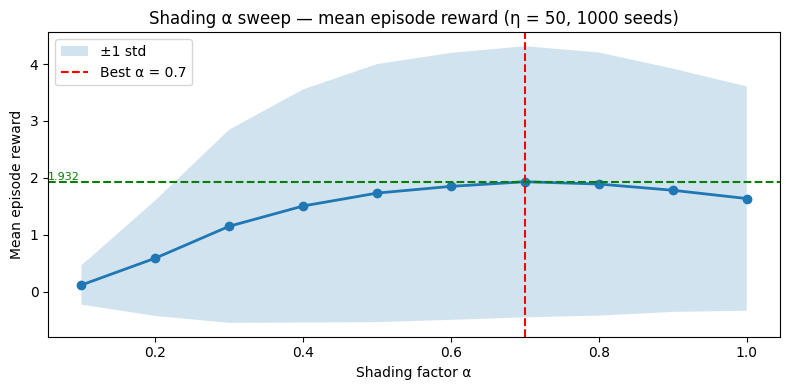

Best α = 0.7  (mean reward = 1.9320)


In [15]:
mean_r = shading_summary_eta50.groupby("alpha")["episode_reward"].mean()
std_r  = shading_summary_eta50.groupby("alpha")["episode_reward"].std()
best_alpha = mean_r.idxmax()
best_reward_eta50 = mean_r.loc[best_alpha]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_alpha, color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.text(
    ax.get_xlim()[0],
    best_reward_eta50,
    f"{best_reward_eta50:.3f}",
    va="bottom",
    ha="left",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axhline(best_reward_eta50, color="green", linestyle="--")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Mean episode reward")
ax.set_title("Shading α sweep — mean episode reward (η = 50, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best α = {best_alpha:.4g}  (mean reward = {best_reward_eta50:.4f})")

/tmp/ipykernel_355218/2157213291.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")


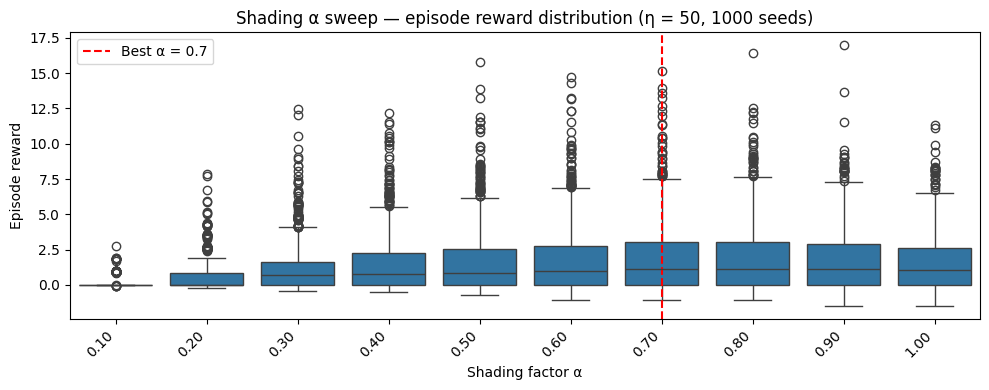

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=shading_summary_eta50, x="alpha", y="episode_reward",
    order=sorted(shading_summary_eta50["alpha"].unique()),
    ax=ax,
)
alphas_sorted = sorted(shading_summary_eta50["alpha"].unique())
ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")
ax.axvline(alphas_sorted.index(best_alpha), color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Episode reward")
ax.set_title("Shading α sweep — episode reward distribution (η = 50, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_dist_eta50.pdf", bbox_inches="tight")
plt.show()

#### Results for $\eta = 100$

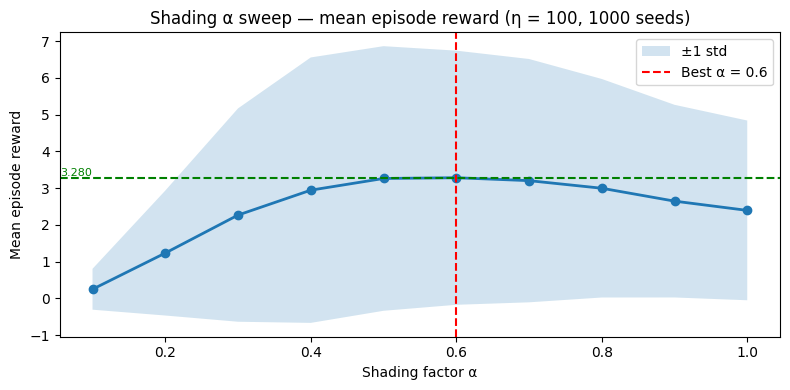

Best α = 0.6  (mean reward = 3.2798)


In [17]:
mean_r = shading_summary_eta100.groupby("alpha")["episode_reward"].mean()
std_r  = shading_summary_eta100.groupby("alpha")["episode_reward"].std()
best_alpha = mean_r.idxmax()
best_reward_eta100 = mean_r.loc[best_alpha]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_alpha, color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.text(
    ax.get_xlim()[0],
    best_reward_eta100,
    f"{best_reward_eta100:.3f}",
    va="bottom",
    ha="left",
    color="green",
    fontsize=8,
    backgroundcolor="none",
)
ax.axhline(best_reward_eta100, color="green", linestyle="--")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Mean episode reward")
ax.set_title("Shading α sweep — mean episode reward (η = 100, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_mean_eta100.pdf", bbox_inches="tight")
plt.show()
print(f"Best α = {best_alpha:.4g}  (mean reward = {best_reward_eta100:.4f})")

/tmp/ipykernel_355218/1711917831.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")


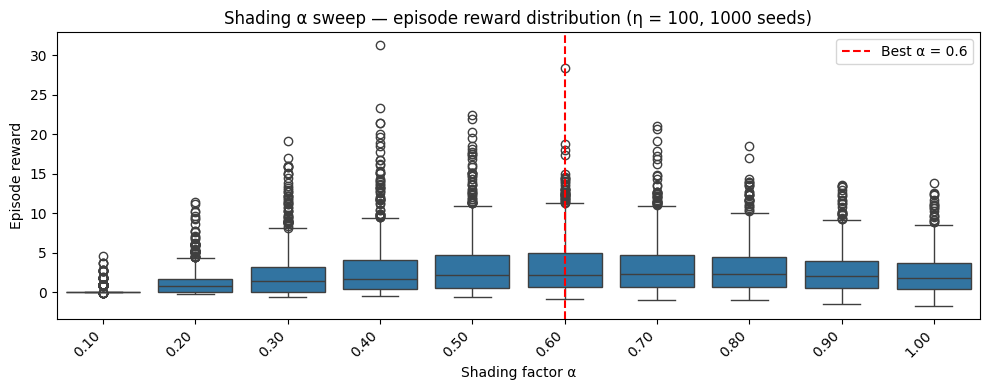

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=shading_summary_eta100, x="alpha", y="episode_reward",
    order=sorted(shading_summary_eta100["alpha"].unique()),
    ax=ax,
)
alphas_sorted = sorted(shading_summary_eta100["alpha"].unique())
ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")
ax.axvline(alphas_sorted.index(best_alpha), color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Episode reward")
ax.set_title("Shading α sweep — episode reward distribution (η = 100, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_dist_eta100.pdf", bbox_inches="tight")
plt.show()

### Sigmoid

#### Results for $\eta = 50$

In [19]:
# Load sigmoid shading alpha sweep CSV (η=50) — use merged file if available
_pattern_sig_alpha = "benchmark_results/sigmoid_results/alpha_shading/survival-second-price-exponential_eta50_sqsigmoid_shading_alpha_sweep_merged.csv"
_files_sig_alpha = sorted(glob.glob(_pattern_sig_alpha))
if not _files_sig_alpha:
    # Fall back to any individual run file
    _pattern_sig_alpha = "benchmark_results/sigmoid_results/alpha_shading/survival-second-price-exponential_eta50_sqsigmoid_shading_alpha_sweep*.csv"
    _files_sig_alpha = sorted(glob.glob(_pattern_sig_alpha))
if not _files_sig_alpha:
    raise FileNotFoundError(
        "No sigmoid shading alpha sweep CSV found.\n"
        "Run:  python benchmark/tune_shading_alpha.py --horizon-eta 50 --squashing sigmoid"
    )

shading_sig_df = pd.read_csv(_files_sig_alpha[-1])
print(f"Loaded: {_files_sig_alpha[-1]}")
print(f"Alphas: {sorted(shading_sig_df['alpha'].unique().round(4).tolist())}")

shading_sig_summary = (
    shading_sig_df.sort_values(["alpha", "seed", "step"])
    .groupby(["alpha", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)

Loaded: benchmark_results/sigmoid_results/alpha_shading/survival-second-price-exponential_eta50_sqsigmoid_shading_alpha_sweep_merged.csv
Alphas: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


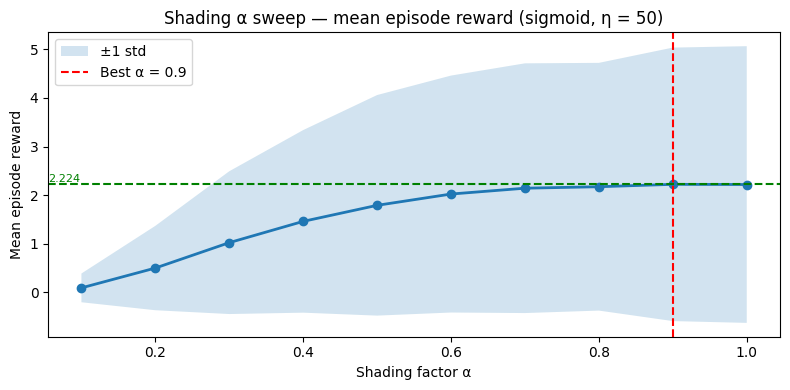

Best α = 0.9  (mean reward = 2.2239)


In [20]:
mean_r = shading_sig_summary.groupby("alpha")["episode_reward"].mean()
std_r  = shading_sig_summary.groupby("alpha")["episode_reward"].std()
best_alpha_sig = mean_r.idxmax()
best_reward_sig = mean_r.loc[best_alpha_sig]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_alpha_sig, color="red", linestyle="--", label=f"Best α = {best_alpha_sig:.4g}")
ax.axhline(best_reward_sig, color="green", linestyle="--")
ax.text(ax.get_xlim()[0], best_reward_sig, f"{best_reward_sig:.3f}",
        va="bottom", ha="left", color="green", fontsize=8)
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Mean episode reward")
ax.set_title("Shading α sweep — mean episode reward (sigmoid, η = 50)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/sigmoid_shading_alpha_sweep_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best α = {best_alpha_sig:.4g}  (mean reward = {best_reward_sig:.4f})")

/tmp/ipykernel_355218/2942102748.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted_sig], rotation=45, ha="right")


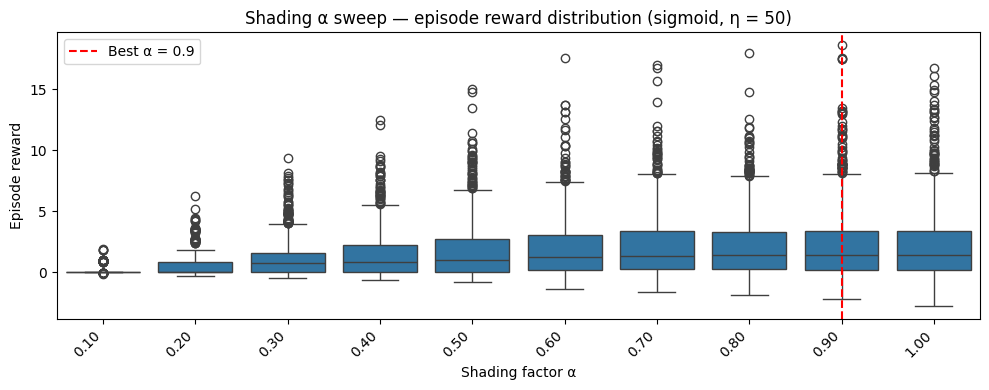

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
alphas_sorted_sig = sorted(shading_sig_summary["alpha"].unique())
sns.boxplot(
    data=shading_sig_summary, x="alpha", y="episode_reward",
    order=alphas_sorted_sig, ax=ax,
)
ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted_sig], rotation=45, ha="right")
ax.axvline(alphas_sorted_sig.index(best_alpha_sig), color="red", linestyle="--",
           label=f"Best α = {best_alpha_sig:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Episode reward")
ax.set_title("Shading α sweep — episode reward distribution (sigmoid, η = 50)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/sigmoid_shading_alpha_sweep_dist_eta50.pdf", bbox_inches="tight")
plt.show()

#### Refined scale (sigmoid, η = 50)

Zoomed sweep over α in the neighbourhood of the best value identified above.

In [22]:
# Load sigmoid shading alpha refined-scale CSVs (η=50)
# "Refined" = files whose alpha range does not start from 0.1 (min alpha > 0.5)
_all_sig_alpha = sorted(glob.glob(
    "benchmark_results/sigmoid_results/alpha_shading/"
    "survival-second-price-exponential_eta50_sqsigmoid_shading_alpha_sweep*.csv"
))
_refined_candidates = []
for _f in _all_sig_alpha:
    _df = pd.read_csv(_f)
    if _df["alpha"].min() > 0.5:
        _refined_candidates.append((_f, _df))

if not _refined_candidates:
    raise FileNotFoundError(
        "No sigmoid refined shading alpha CSV found (expected min alpha > 0.5).\n"
        "Run:  python benchmark/tune_shading_alpha.py --horizon-eta 50 --squashing sigmoid "
        "--alpha-min 0.85 --alpha-max 1.1 --n-alphas 10"
    )

# Use the most recent
shading_sig_refined_file, shading_sig_refined_df = _refined_candidates[-1]
print(f"Loaded: {shading_sig_refined_file}")
print(f"Alphas: {sorted(shading_sig_refined_df['alpha'].unique().round(4).tolist())}")

shading_sig_refined_summary = (
    shading_sig_refined_df.sort_values(["alpha", "seed", "step"])
    .groupby(["alpha", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)

Loaded: benchmark_results/sigmoid_results/alpha_shading/survival-second-price-exponential_eta50_sqsigmoid_shading_alpha_sweep_finer_scale_2026-06-05_14-08-51.csv
Alphas: [0.85, 0.8875, 0.925, 0.9625, 1.0]


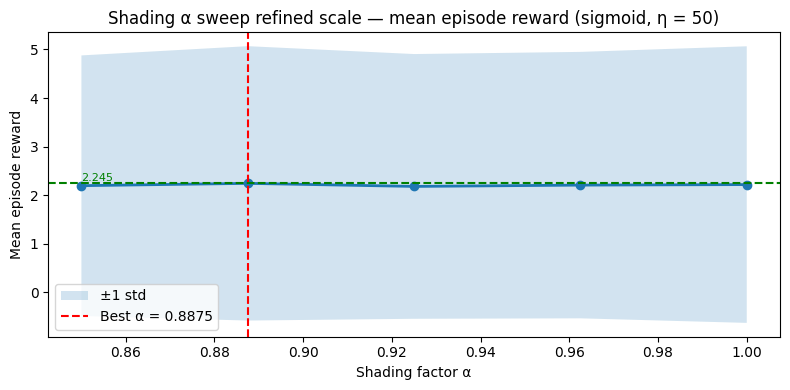

Best α = 0.8875  (mean reward = 2.2452)


In [23]:
mean_r = shading_sig_refined_summary.groupby("alpha")["episode_reward"].mean()
std_r  = shading_sig_refined_summary.groupby("alpha")["episode_reward"].std()
best_alpha_sig_refined = mean_r.idxmax()
best_reward_sig_refined = mean_r.loc[best_alpha_sig_refined]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_alpha_sig_refined, color="red", linestyle="--",
           label=f"Best α = {best_alpha_sig_refined:.4g}")
ax.axhline(best_reward_sig_refined, color="green", linestyle="--")
ax.text(mean_r.index[0], best_reward_sig_refined, f"{best_reward_sig_refined:.3f}",
        va="bottom", ha="left", color="green", fontsize=8)
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Mean episode reward")
ax.set_title("Shading α sweep refined scale — mean episode reward (sigmoid, η = 50)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/sigmoid_shading_alpha_sweep_refined_mean_eta50.pdf", bbox_inches="tight")
plt.show()
print(f"Best α = {best_alpha_sig_refined:.4g}  (mean reward = {best_reward_sig_refined:.4f})")

/tmp/ipykernel_355218/547848985.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{a:.3f}" for a in alphas_sorted_sig_refined], rotation=45, ha="right")


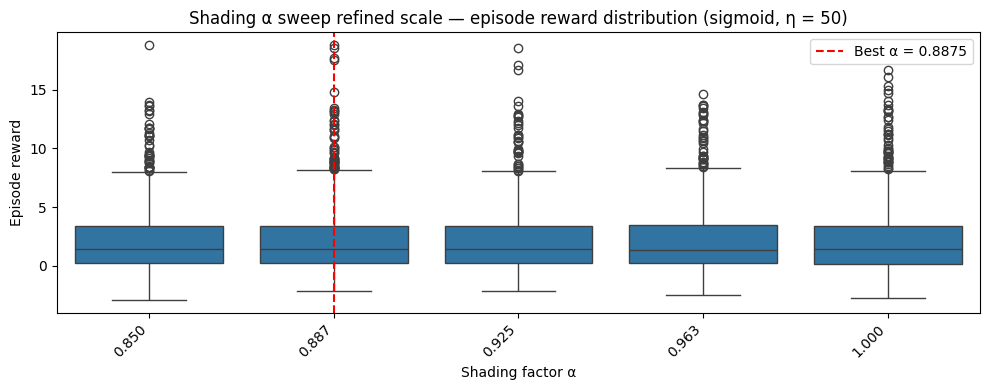

In [24]:
fig, ax = plt.subplots(figsize=(10, 4))
alphas_sorted_sig_refined = sorted(shading_sig_refined_summary["alpha"].unique())
sns.boxplot(
    data=shading_sig_refined_summary, x="alpha", y="episode_reward",
    order=alphas_sorted_sig_refined, ax=ax,
)
ax.set_xticklabels([f"{a:.3f}" for a in alphas_sorted_sig_refined], rotation=45, ha="right")
ax.axvline(alphas_sorted_sig_refined.index(best_alpha_sig_refined), color="red", linestyle="--",
           label=f"Best α = {best_alpha_sig_refined:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Episode reward")
ax.set_title("Shading α sweep refined scale — episode reward distribution (sigmoid, η = 50)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/sigmoid_shading_alpha_sweep_refined_dist_eta50.pdf", bbox_inches="tight")
plt.show()

## 1. Load results

Load the saved per-step CSV and build the score matrix (total episode reward per policy per seed) used by rliable.

In [25]:
_pattern_final_results_eta50 = "benchmark_results/clip_results/survival-second-price-exponential_eta50_results_final.csv"
_files_final_results_eta50 = sorted(glob.glob(_pattern_final_results_eta50))
if not _files_final_results_eta50:
    raise FileNotFoundError(
        f"No final results CSV found matching {_pattern_final_results_eta50!r}.\n"
        "Run:  python benchmark/run_all.py --horizon-eta 50"
    )
df_eta50 = pd.read_csv(_files_final_results_eta50[-1])

In [26]:
_pattern_final_results_eta100 = "benchmark_results/clip_results/survival-second-price-exponential_eta100_results_final.csv"
_files_final_results_eta100 = sorted(glob.glob(_pattern_final_results_eta100))
if not _files_final_results_eta100:
    raise FileNotFoundError(
        f"No final results CSV found matching {_pattern_final_results_eta100!r}.\n"
        "Run:  python benchmark/run_all.py --horizon-eta 100"
    )
df_eta100 = pd.read_csv(_files_final_results_eta100[-1])

In [27]:
_pattern_final_results_eta50_sigmoid = "benchmark_results/sigmoid_results/survival-second-price-exponential_eta50_sigmoid_results_final.csv"
_files_final_results_eta50_sigmoid = sorted(glob.glob(_pattern_final_results_eta50_sigmoid))
if not _files_final_results_eta50_sigmoid:
    raise FileNotFoundError(
        f"No final results CSV found matching {_pattern_final_results_eta50_sigmoid!r}.\n"
        "Run the sigmoid evaluate.py jobs and merge with benchmark/merge_eval_results.py"
    )
df_eta50_sigmoid = pd.read_csv(_files_final_results_eta50_sigmoid[-1])

In [28]:
scores_eta50 = score_matrix(df_eta50)

In [29]:
scores_eta50_sigmoid = score_matrix(df_eta50_sigmoid)

In [30]:
scores_eta100 = score_matrix(df_eta100)

Mean number of auction opportunities per episode across all seeds. The horizon is exponentially distributed with rate 1/η, giving a mean campaign length of η auctions.

In [31]:
algos_list = df_eta100["policy"].unique()
algos_list

<StringArray>
[                  'FiPla',            'GreedyMyopic',
               'MPC(H=10)',               'MPC(H=25)',
 'MPCTimeBinned(H=10,K=2)', 'MPCTimeBinned(H=10,K=3)',
 'MPCTimeBinned(H=25,K=2)', 'MPCTimeBinned(H=25,K=3)',
                     'SAC',                     'TD3',
        'Constant(0.2105)',          'Shading(α=0.6)',
                     'PPO']
Length: 13, dtype: str

## 2. Plots

### Aggregate metrics

IQM, mean, median, and optimality gap of episode reward across 1000 seeds, with stratified bootstrap confidence intervals (rliable).

#### Clip :

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/aggregate_metrics_eta50.pdf


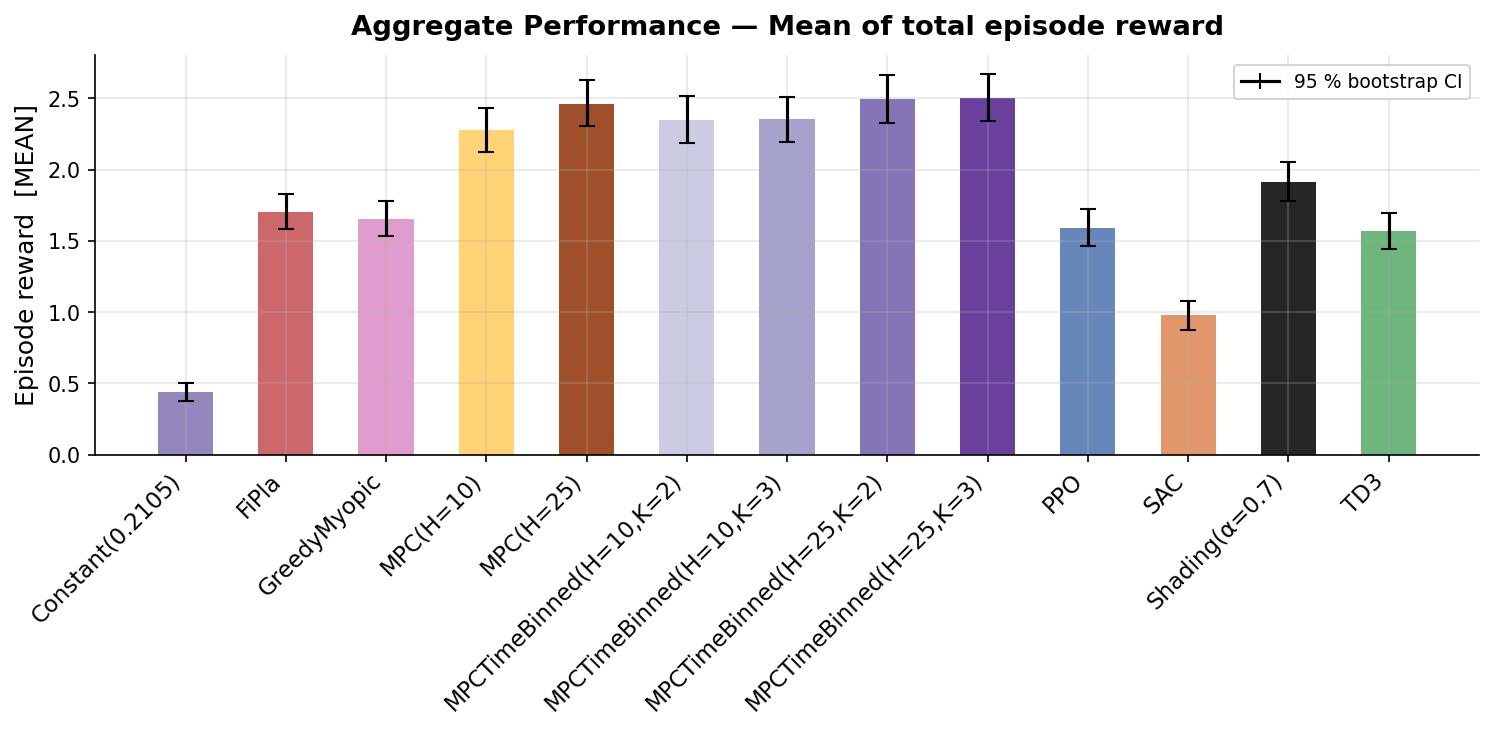

In [32]:
_ = plots.plot_aggregate_metrics(scores_eta50, metric="mean", normalize_by=None, filename="aggregate_metrics_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/aggregate_metrics_eta100.pdf


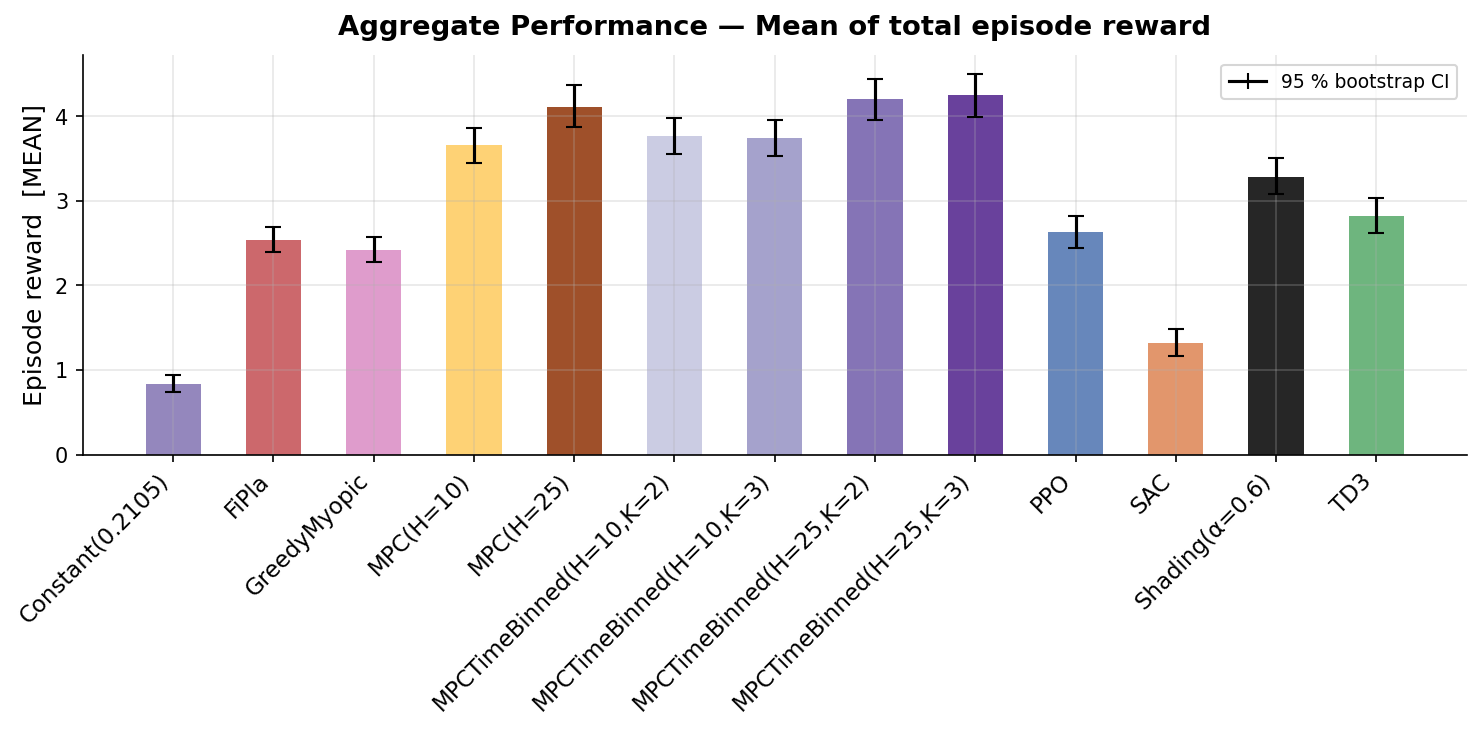

In [33]:
_ = plots.plot_aggregate_metrics(scores_eta100, metric="mean", normalize_by=None, filename="aggregate_metrics_eta100.pdf")

#### Sigmoid :

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/aggregate_metrics_eta50_sigmoid.pdf


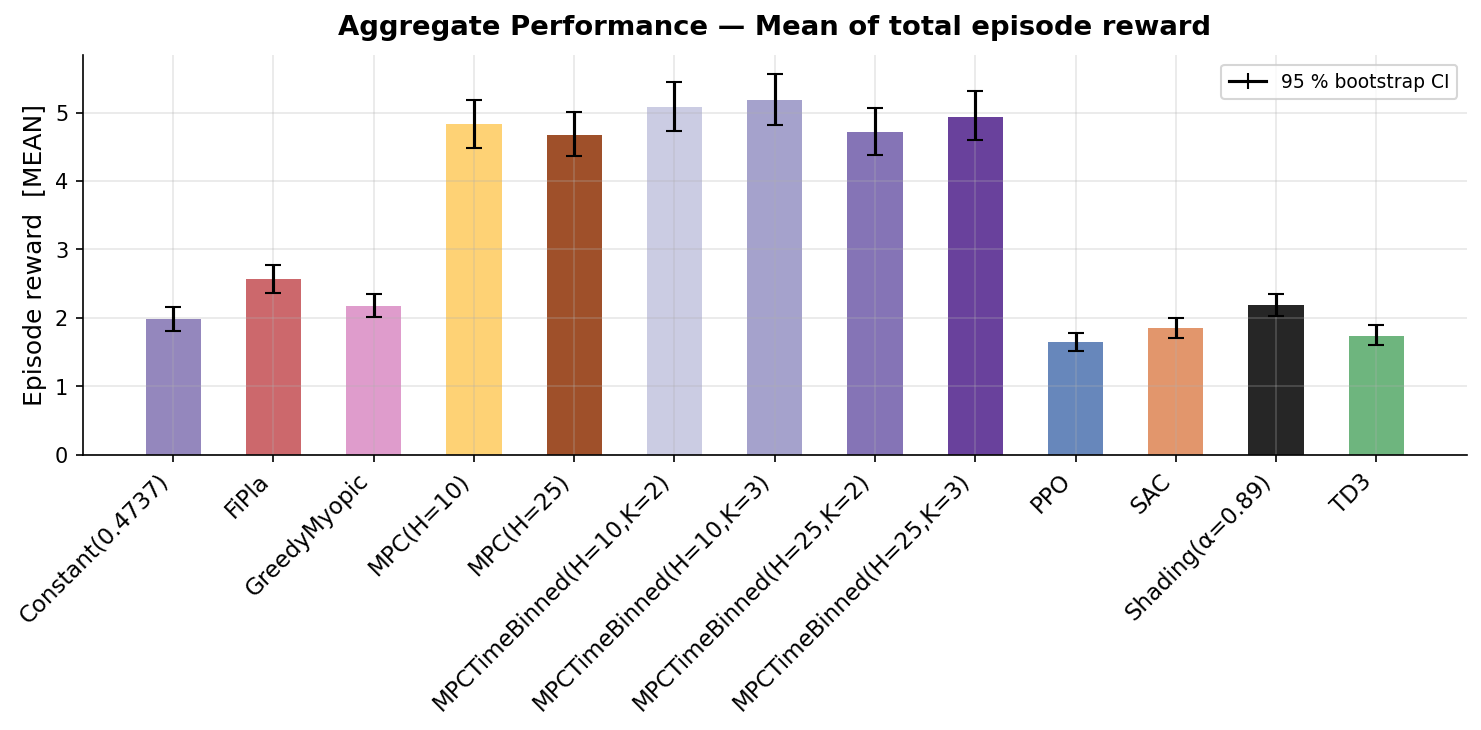

In [34]:
_ = plots.plot_aggregate_metrics(scores_eta50_sigmoid, metric="mean", normalize_by=None, filename="aggregate_metrics_eta50_sigmoid.pdf")

### Performance profiles

Fraction of seeds on which each policy achieves at least a given score threshold τ. A curve that is higher and further to the right indicates more consistent performance across seeds.

### Clip :

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/performance_profiles_eta50.pdf


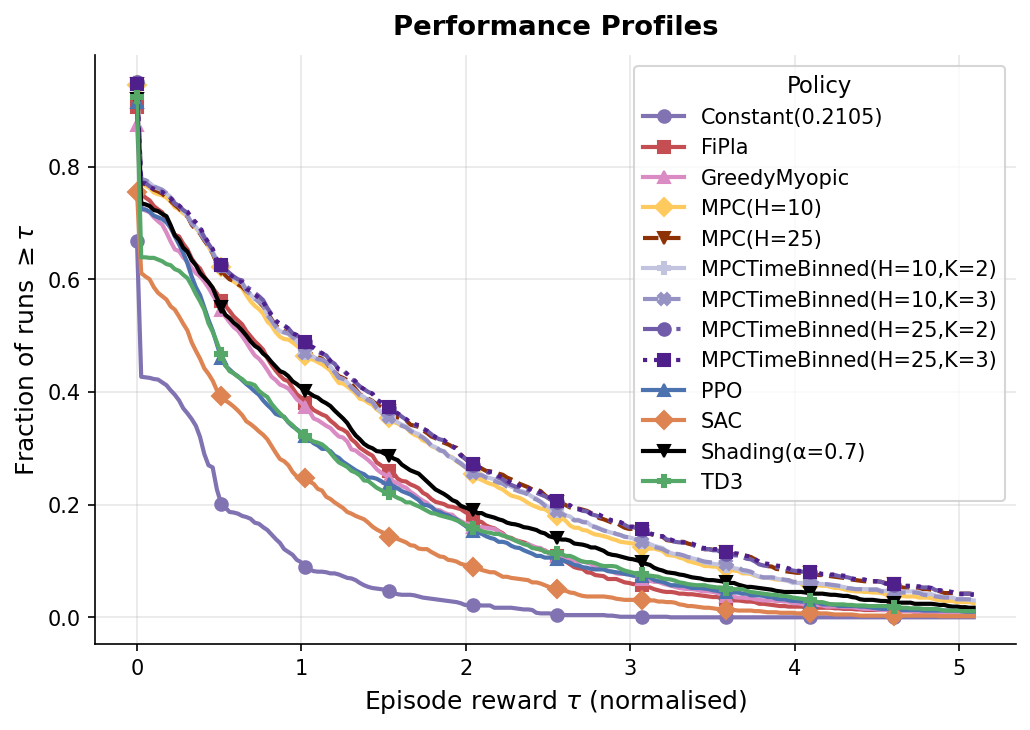

In [35]:
_ = plots.plot_performance_profiles(scores_eta50, filename="performance_profiles_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/performance_profiles_eta100.pdf


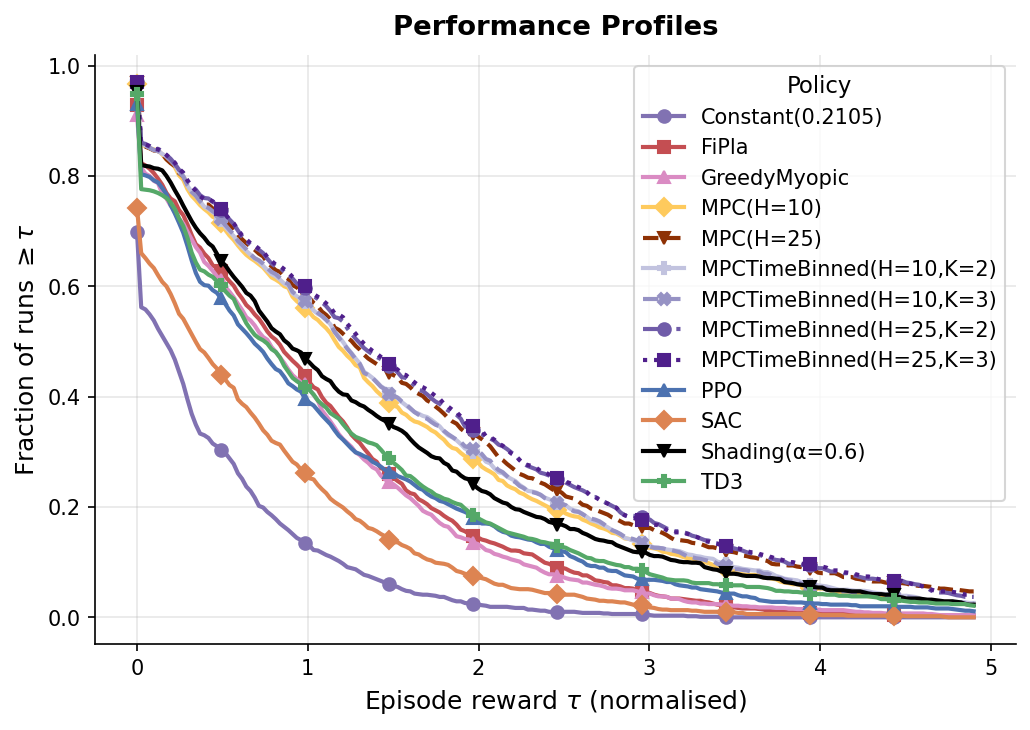

In [36]:
_ = plots.plot_performance_profiles(scores_eta100, filename="performance_profiles_eta100.pdf")

#### Sigmoid :

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/performance_profiles_eta50_sigmoid.pdf


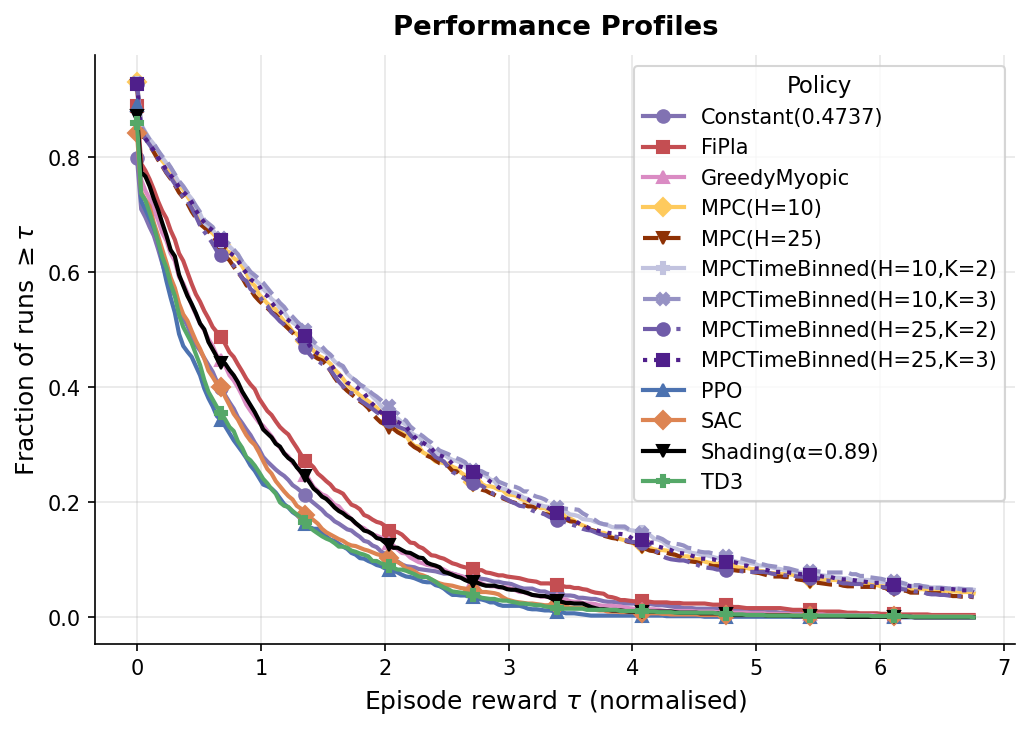

In [37]:
_ = plots.plot_performance_profiles(scores_eta50_sigmoid, filename="performance_profiles_eta50_sigmoid.pdf")

### Cumulative reward over time

Mean cumulative reward as a function of **normalised campaign time** (each episode's
time axis is rescaled to [0, 1] before averaging), across 1 000 seeds.
Shaded bands show ±1 standard deviation.

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/cumulative_reward_eta50.pdf


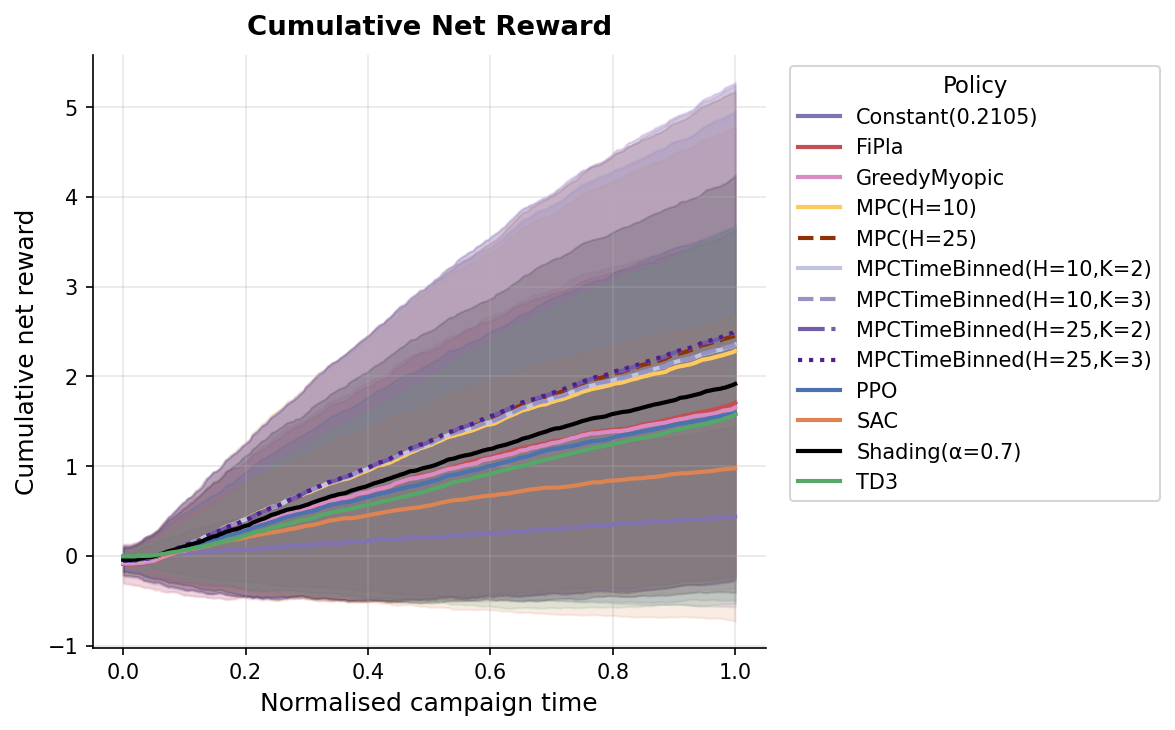

In [38]:
_ = plots.plot_cumulative_reward(df_eta50, filename="cumulative_reward_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/cumulative_reward_eta100.pdf


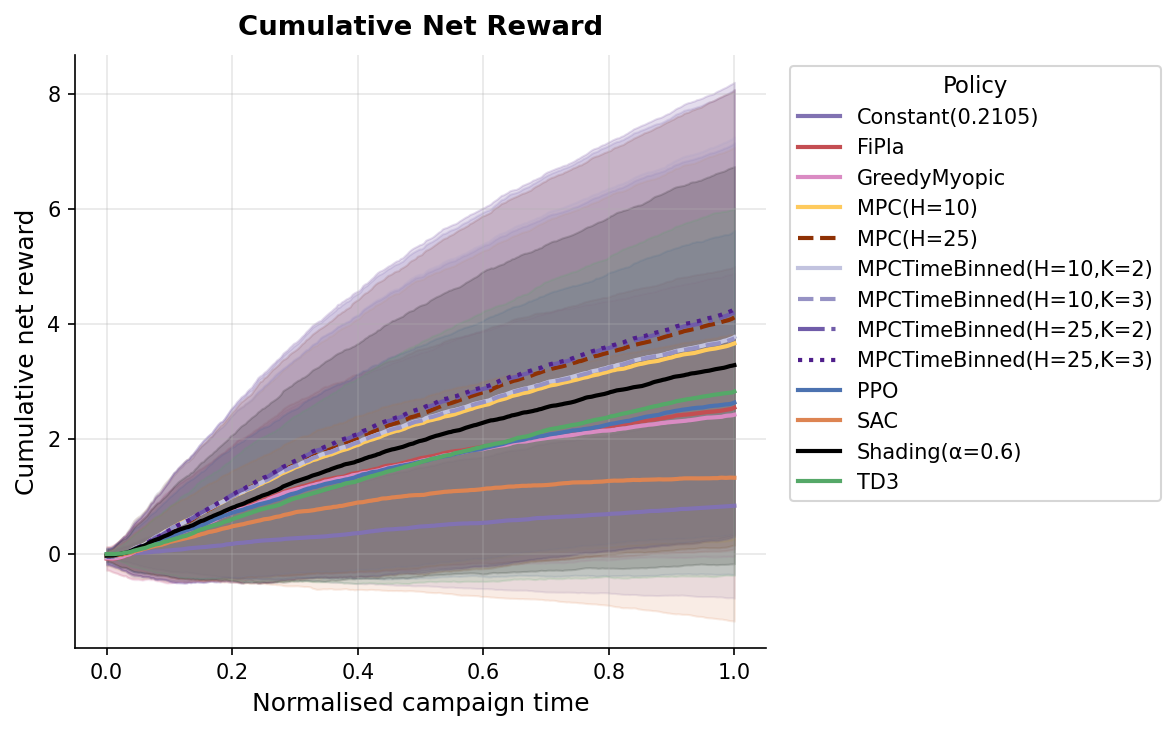

In [39]:
_ = plots.plot_cumulative_reward(df_eta100, filename="cumulative_reward_eta100.pdf")

#### Sigmoid :

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/cumulative_reward_eta50_sigmoid.pdf


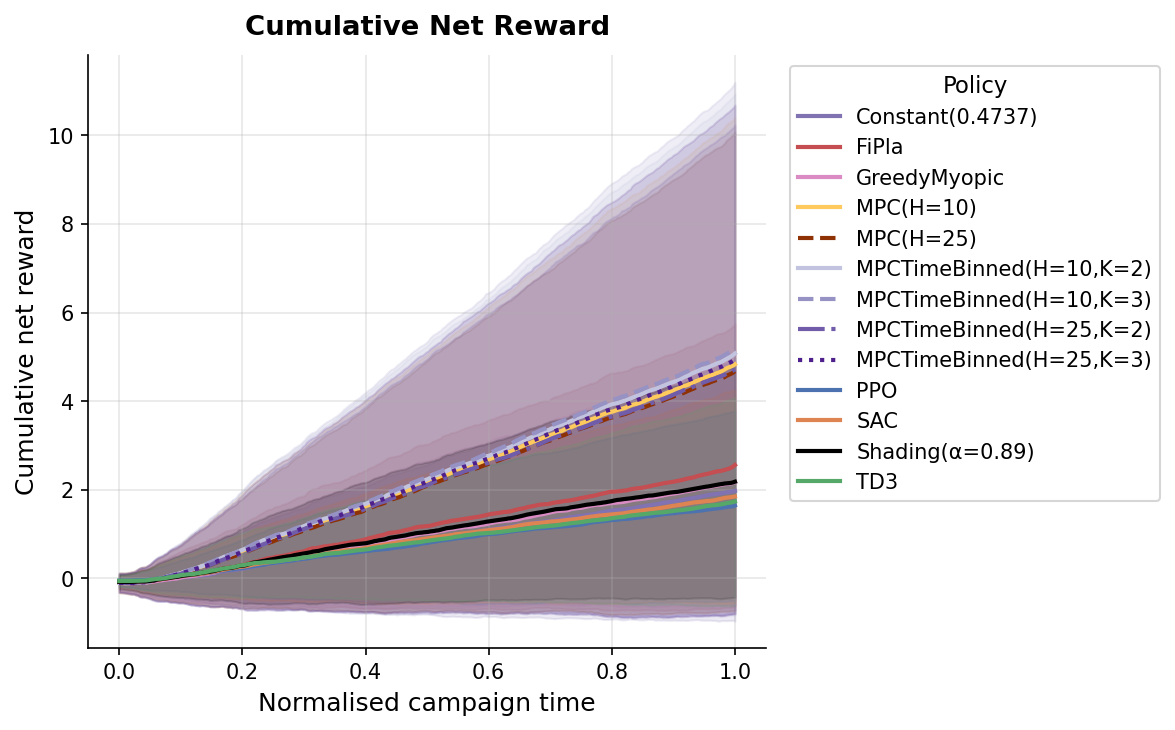

In [40]:
_ = plots.plot_cumulative_reward(df_eta50_sigmoid, filename="cumulative_reward_eta50_sigmoid.pdf")

### Episode reward distribution

Distribution of total episode reward across 1000 seeds for each policy.

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:412: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",
/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:421: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/reward_distribution_eta50.pdf


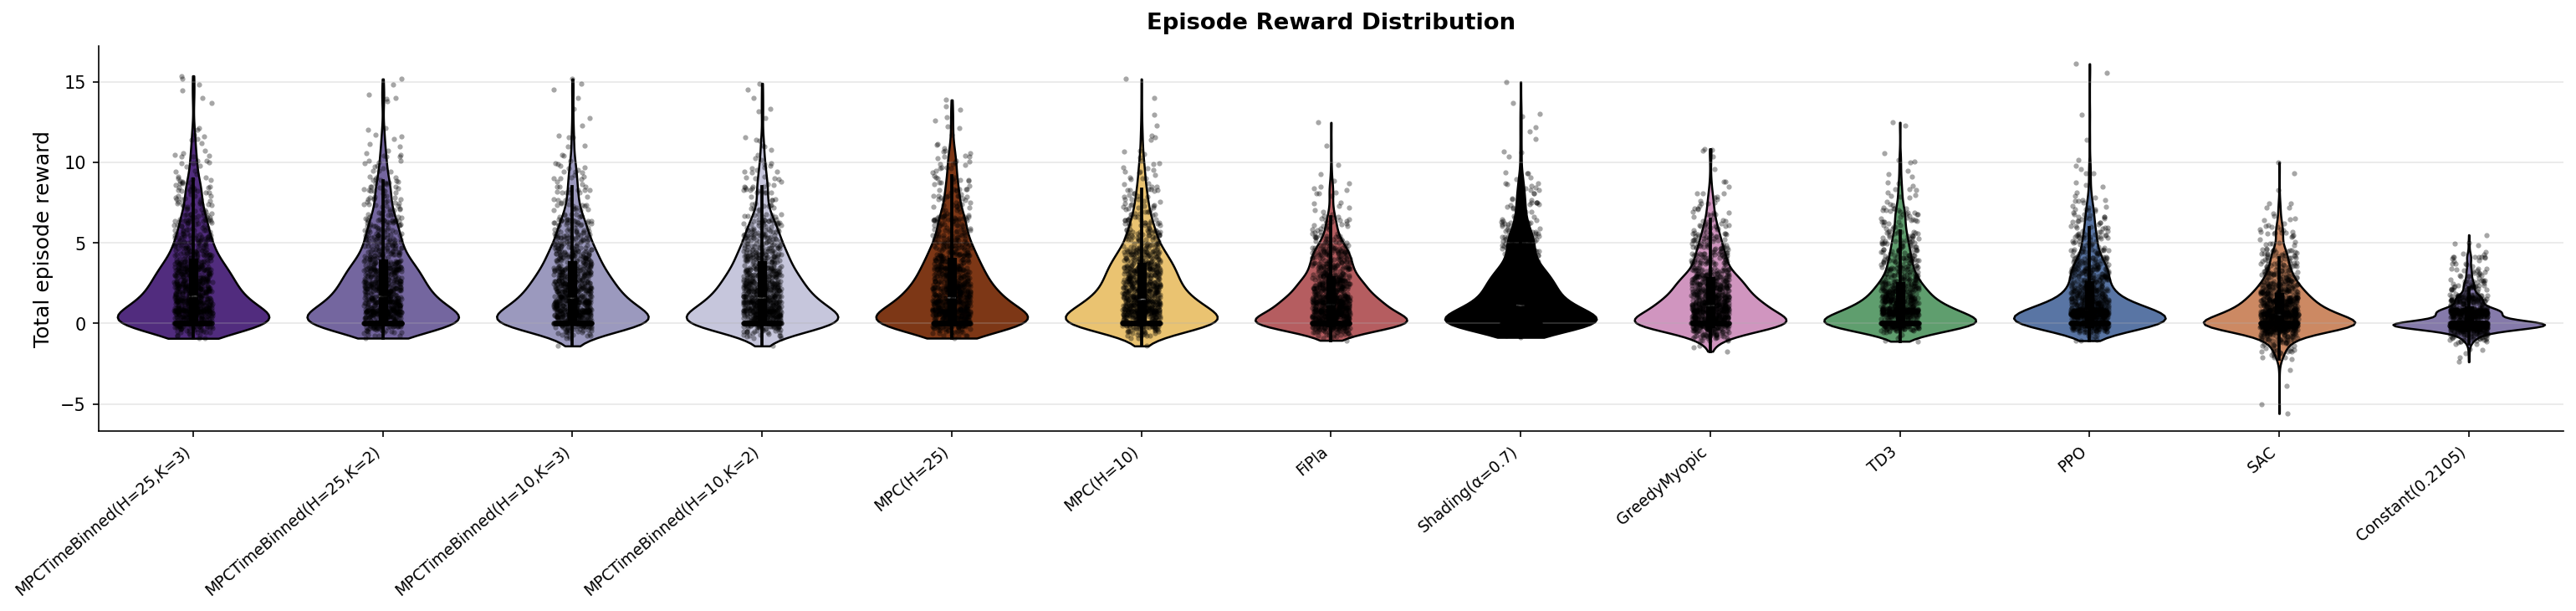

In [41]:
_ = plots.plot_reward_distribution(df_eta50, filename="reward_distribution_eta50.pdf")

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:412: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",


/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:421: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/reward_distribution_eta100.pdf


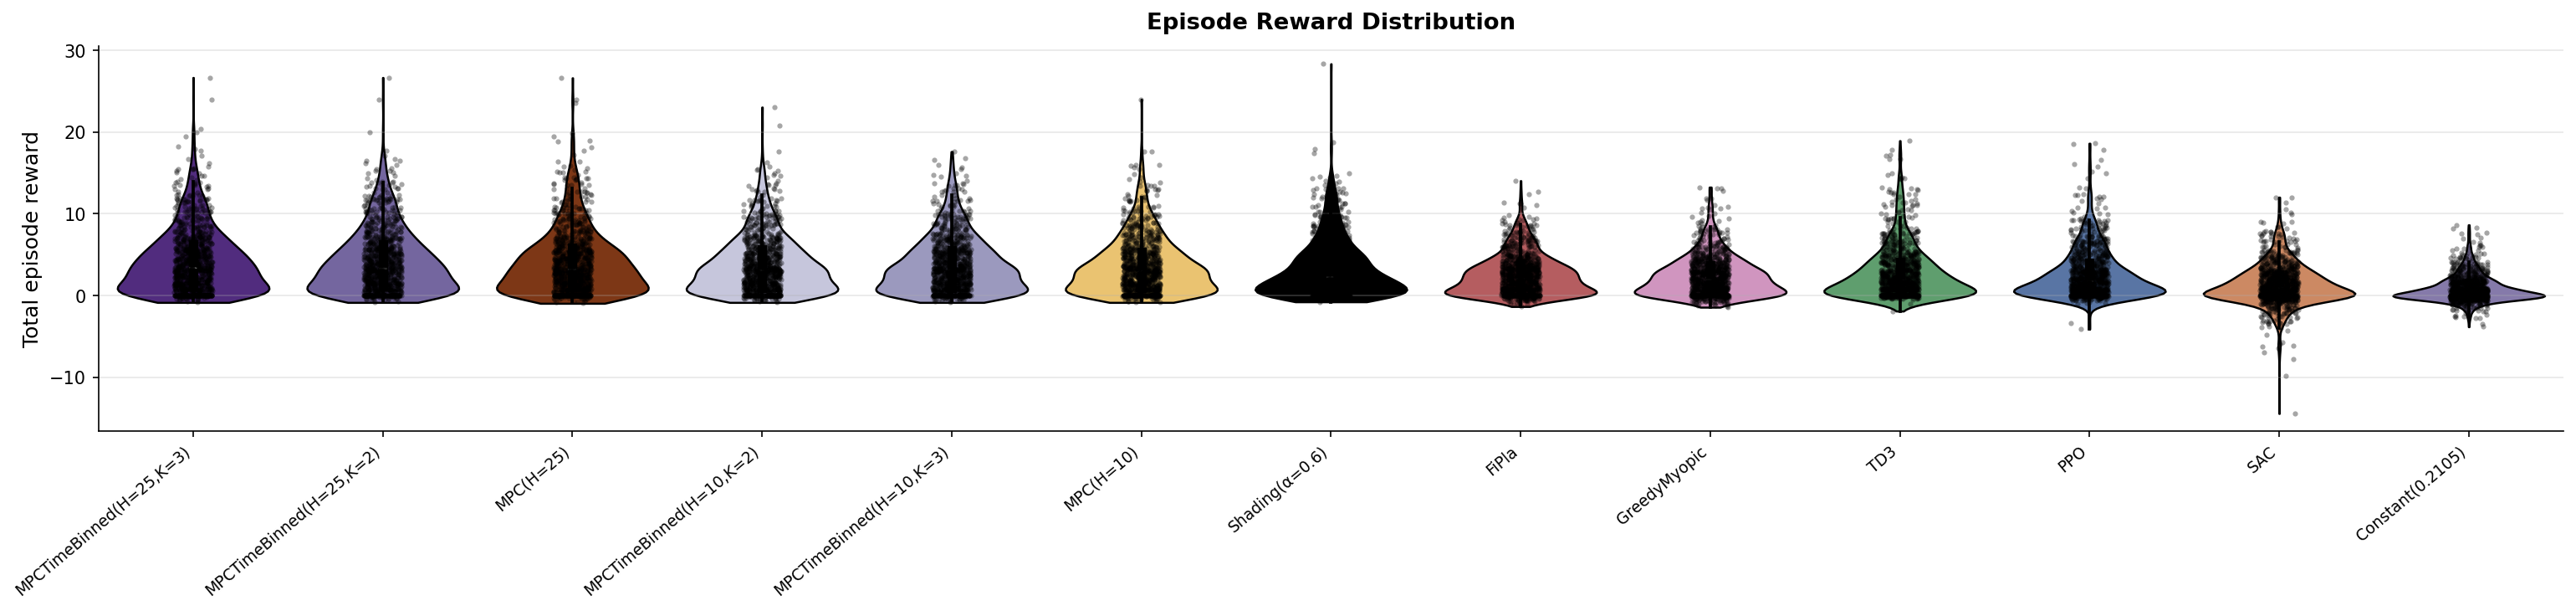

In [42]:
_ = plots.plot_reward_distribution(df_eta100, filename="reward_distribution_eta100.pdf")

#### Sigmoid :

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:412: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",
/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:421: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/reward_distribution_eta50_sigmoid.pdf


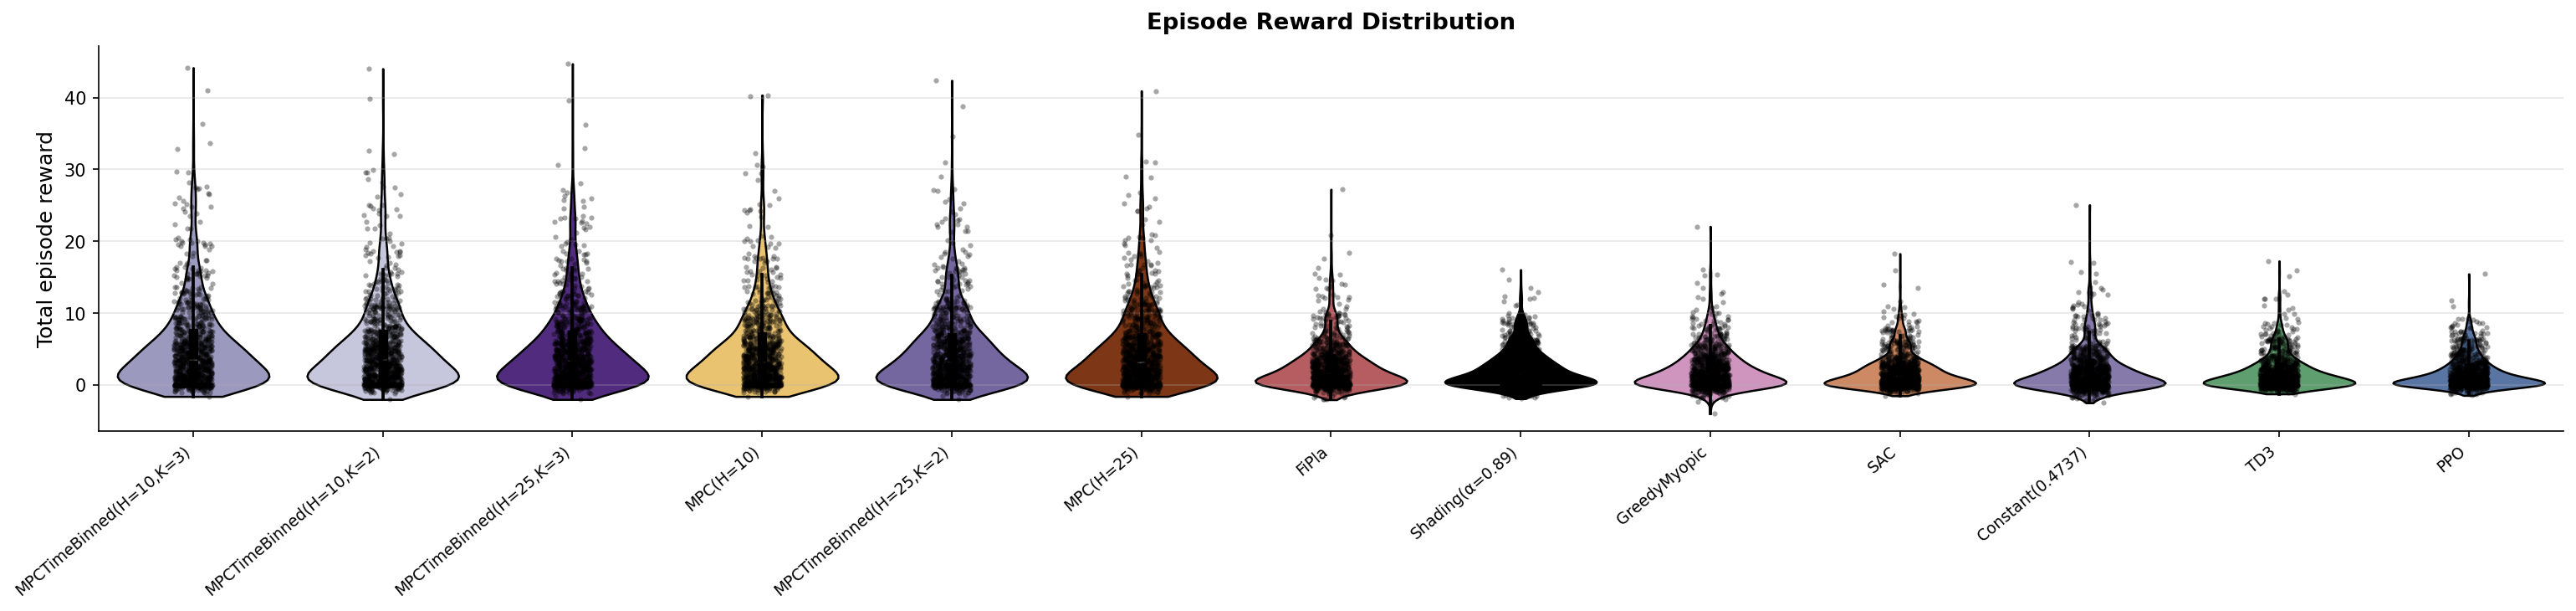

In [43]:
_ = plots.plot_reward_distribution(df_eta50_sigmoid, filename="reward_distribution_eta50_sigmoid.pdf")

### Context dynamics

Evolution of the context signal `ctx` and the expected reward over **normalised
campaign time** (rescaled to [0, 1] per seed), averaged across 1 000 seeds.
Illustrates how the survival kernel erodes the display value as the campaign progresses.

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/context_dynamics_eta50.pdf


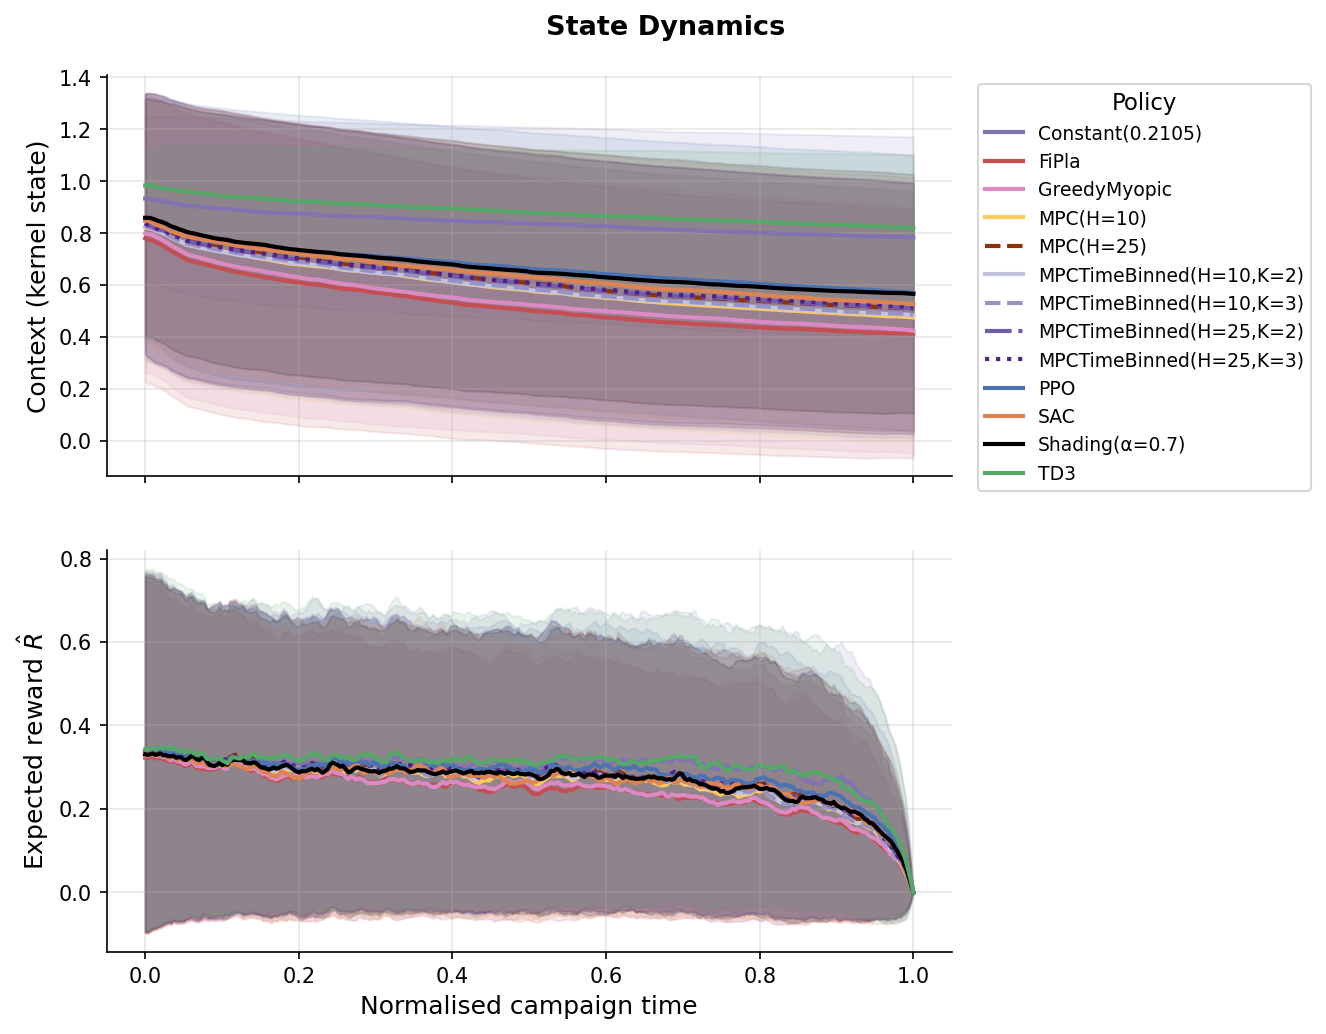

In [44]:
_ = plots.plot_context_dynamics(df_eta50, filename="context_dynamics_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/context_dynamics_eta100.pdf


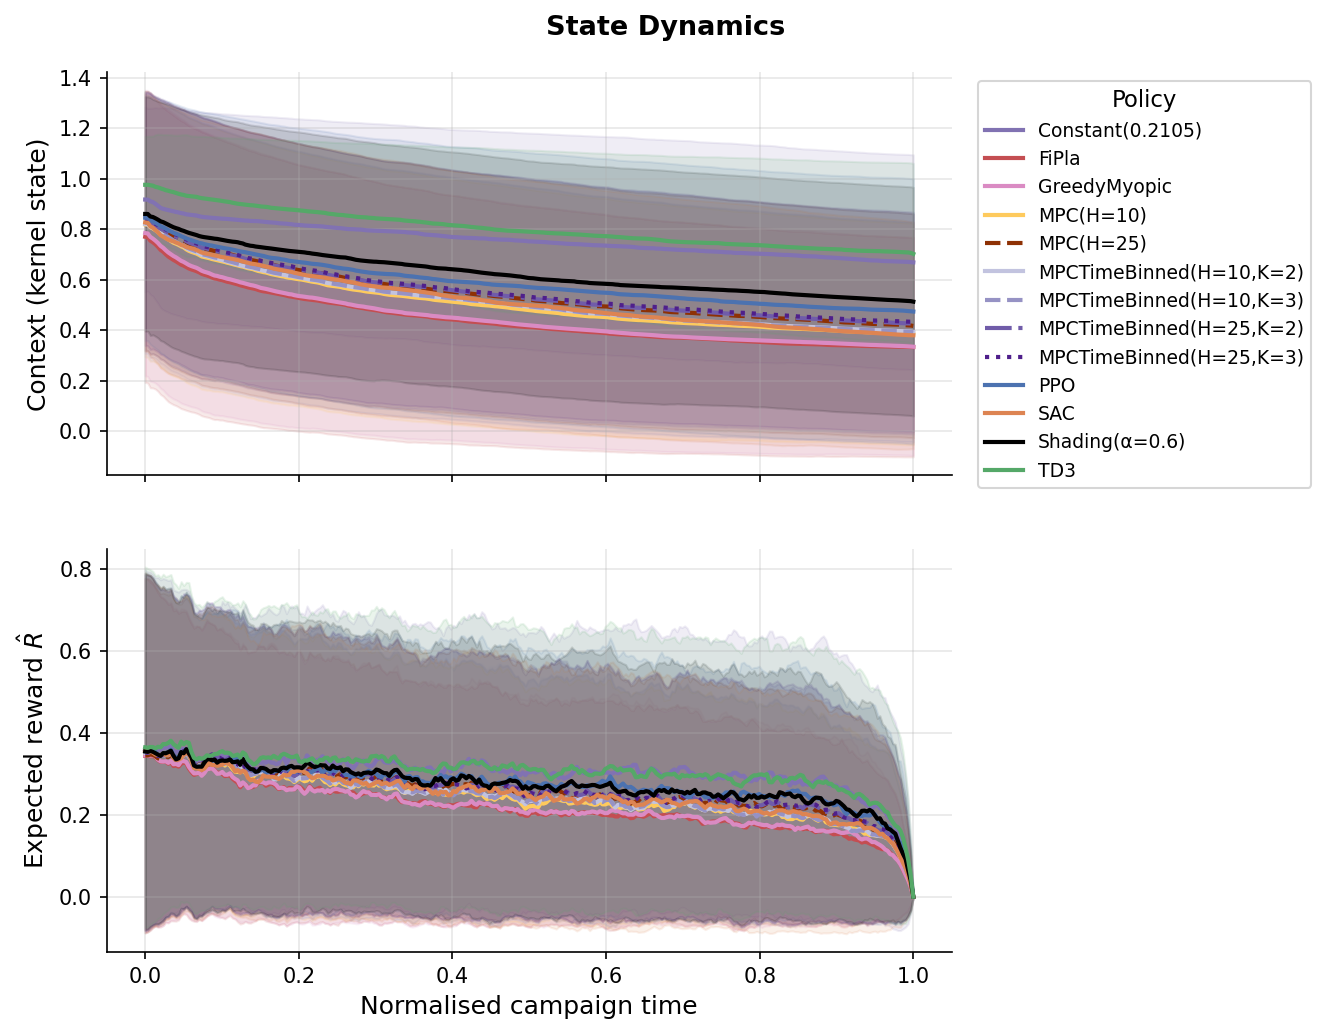

In [45]:
_ = plots.plot_context_dynamics(df_eta100, filename="context_dynamics_eta100.pdf")

#### Sigmoid :

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/context_dynamics_eta50_sigmoid.pdf


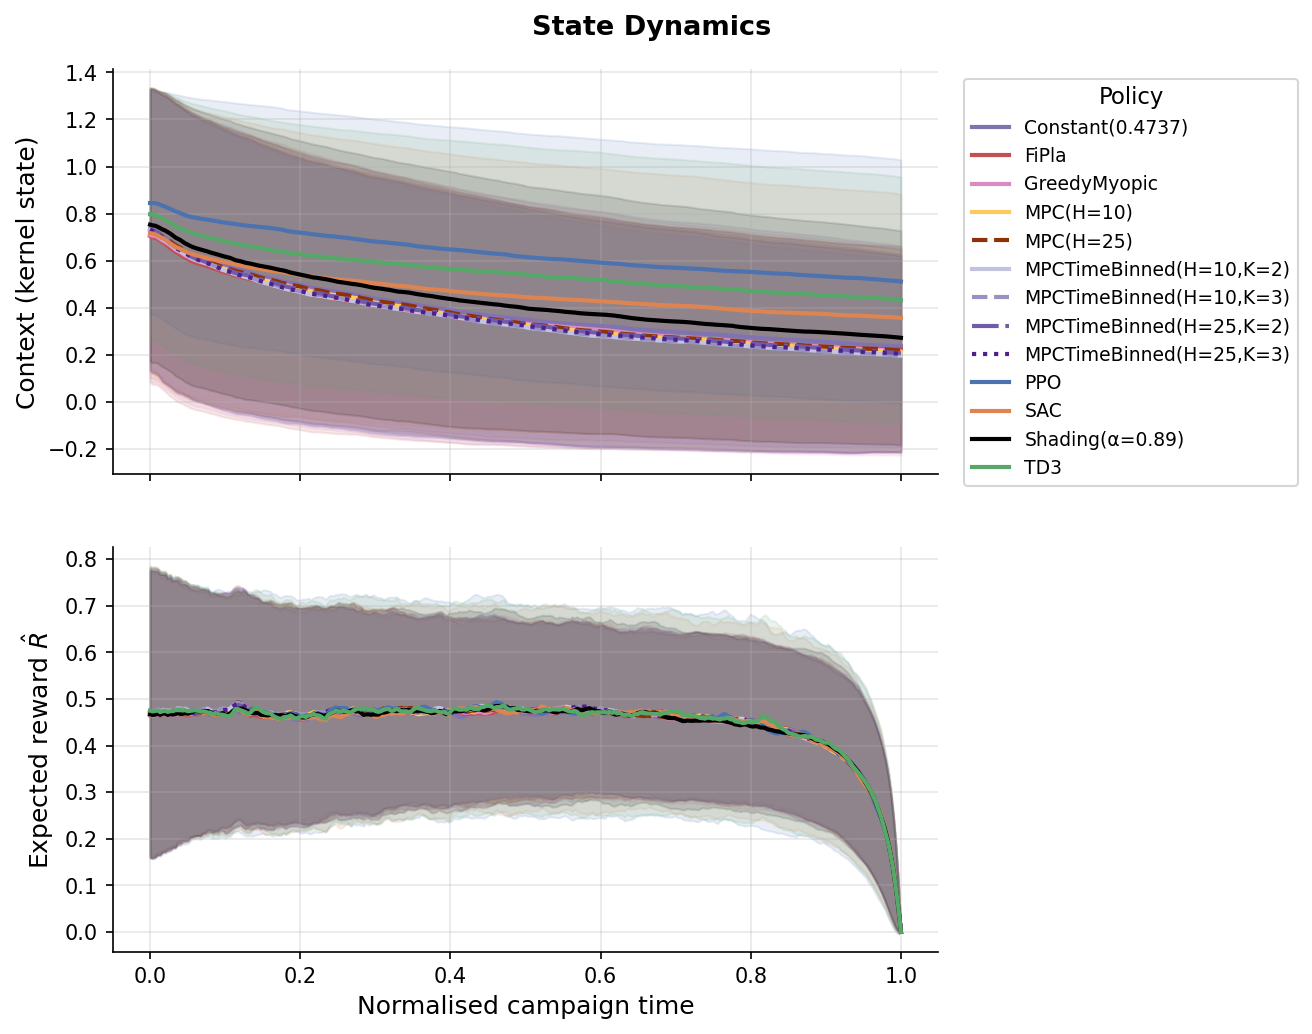

In [46]:
_ = plots.plot_context_dynamics(df_eta50_sigmoid, filename="context_dynamics_eta50_sigmoid.pdf")

### Bid distributions

Distribution of submitted bids across all steps and seeds for each policy, overlaid with the expected value signal (`expected_reward`). Shows how well each policy aligns bids with true values.

#### Clipe : 

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:611: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(bids, ax=ax, color=color, lw=2,


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/bid_distributions_eta50.pdf


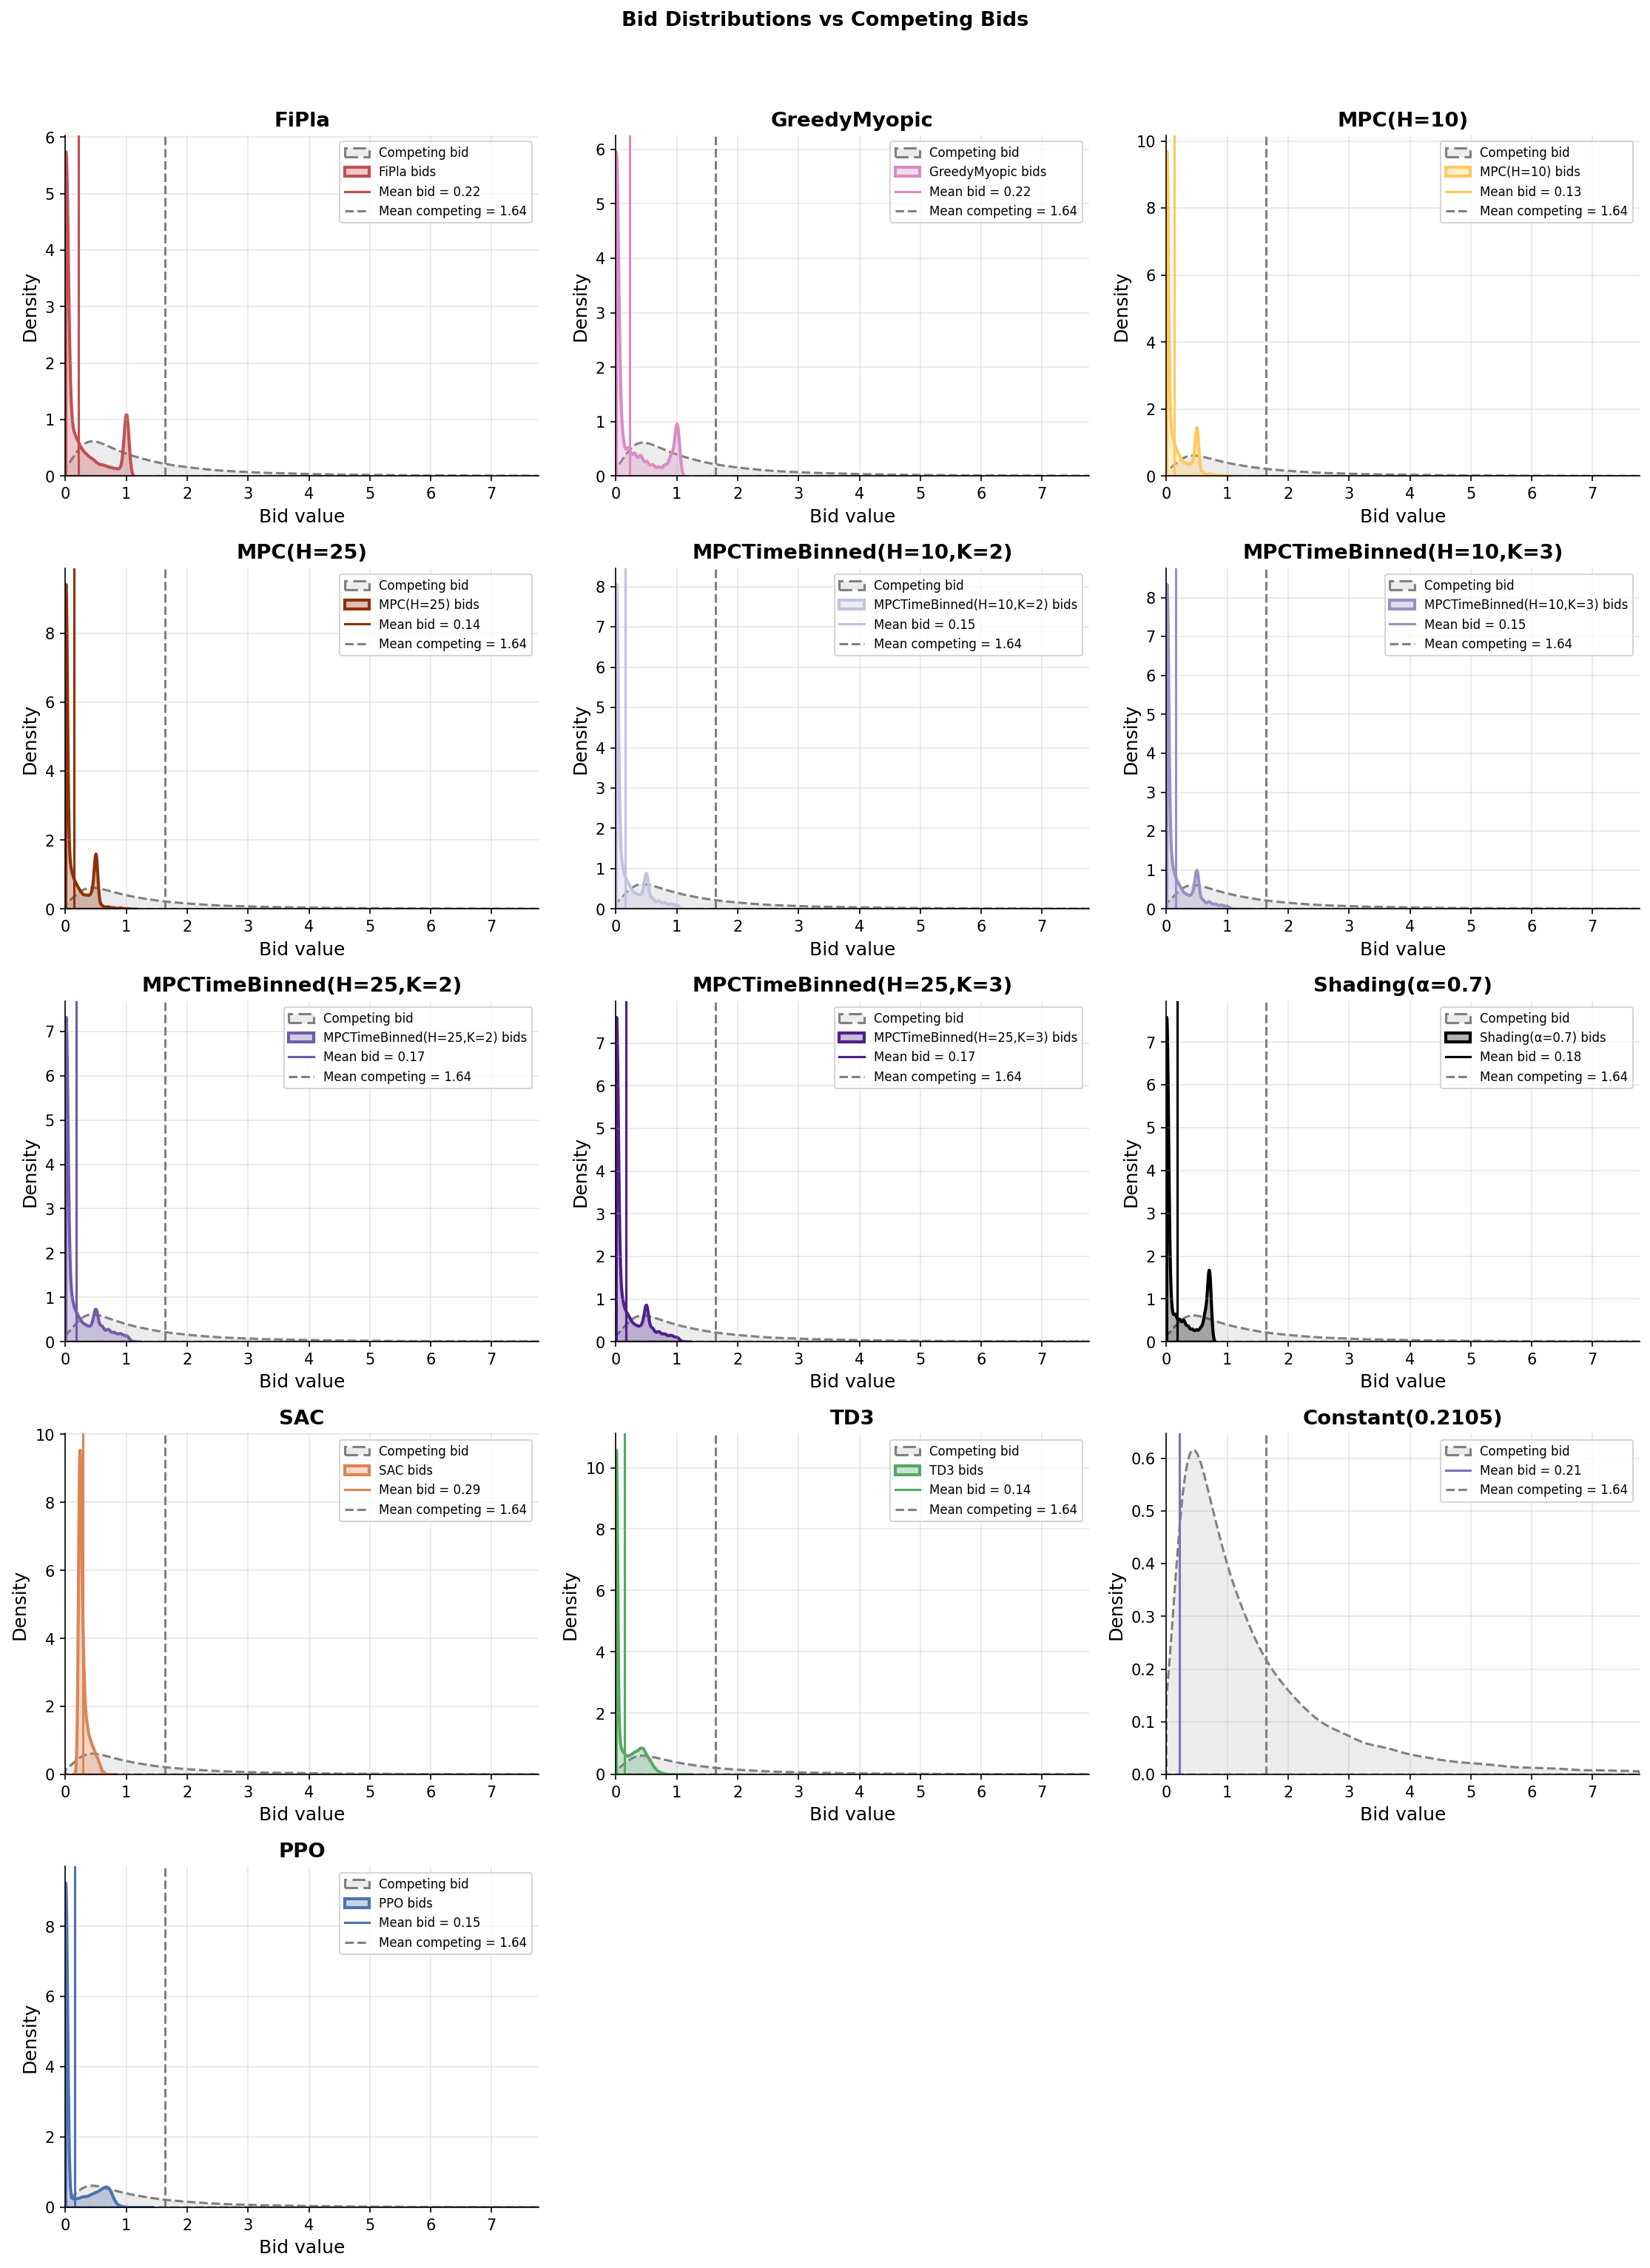

In [47]:
_ = plots.plot_bid_distributions(df_eta50, filename="bid_distributions_eta50.pdf")

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:611: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(bids, ax=ax, color=color, lw=2,


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/bid_distributions_eta100.pdf


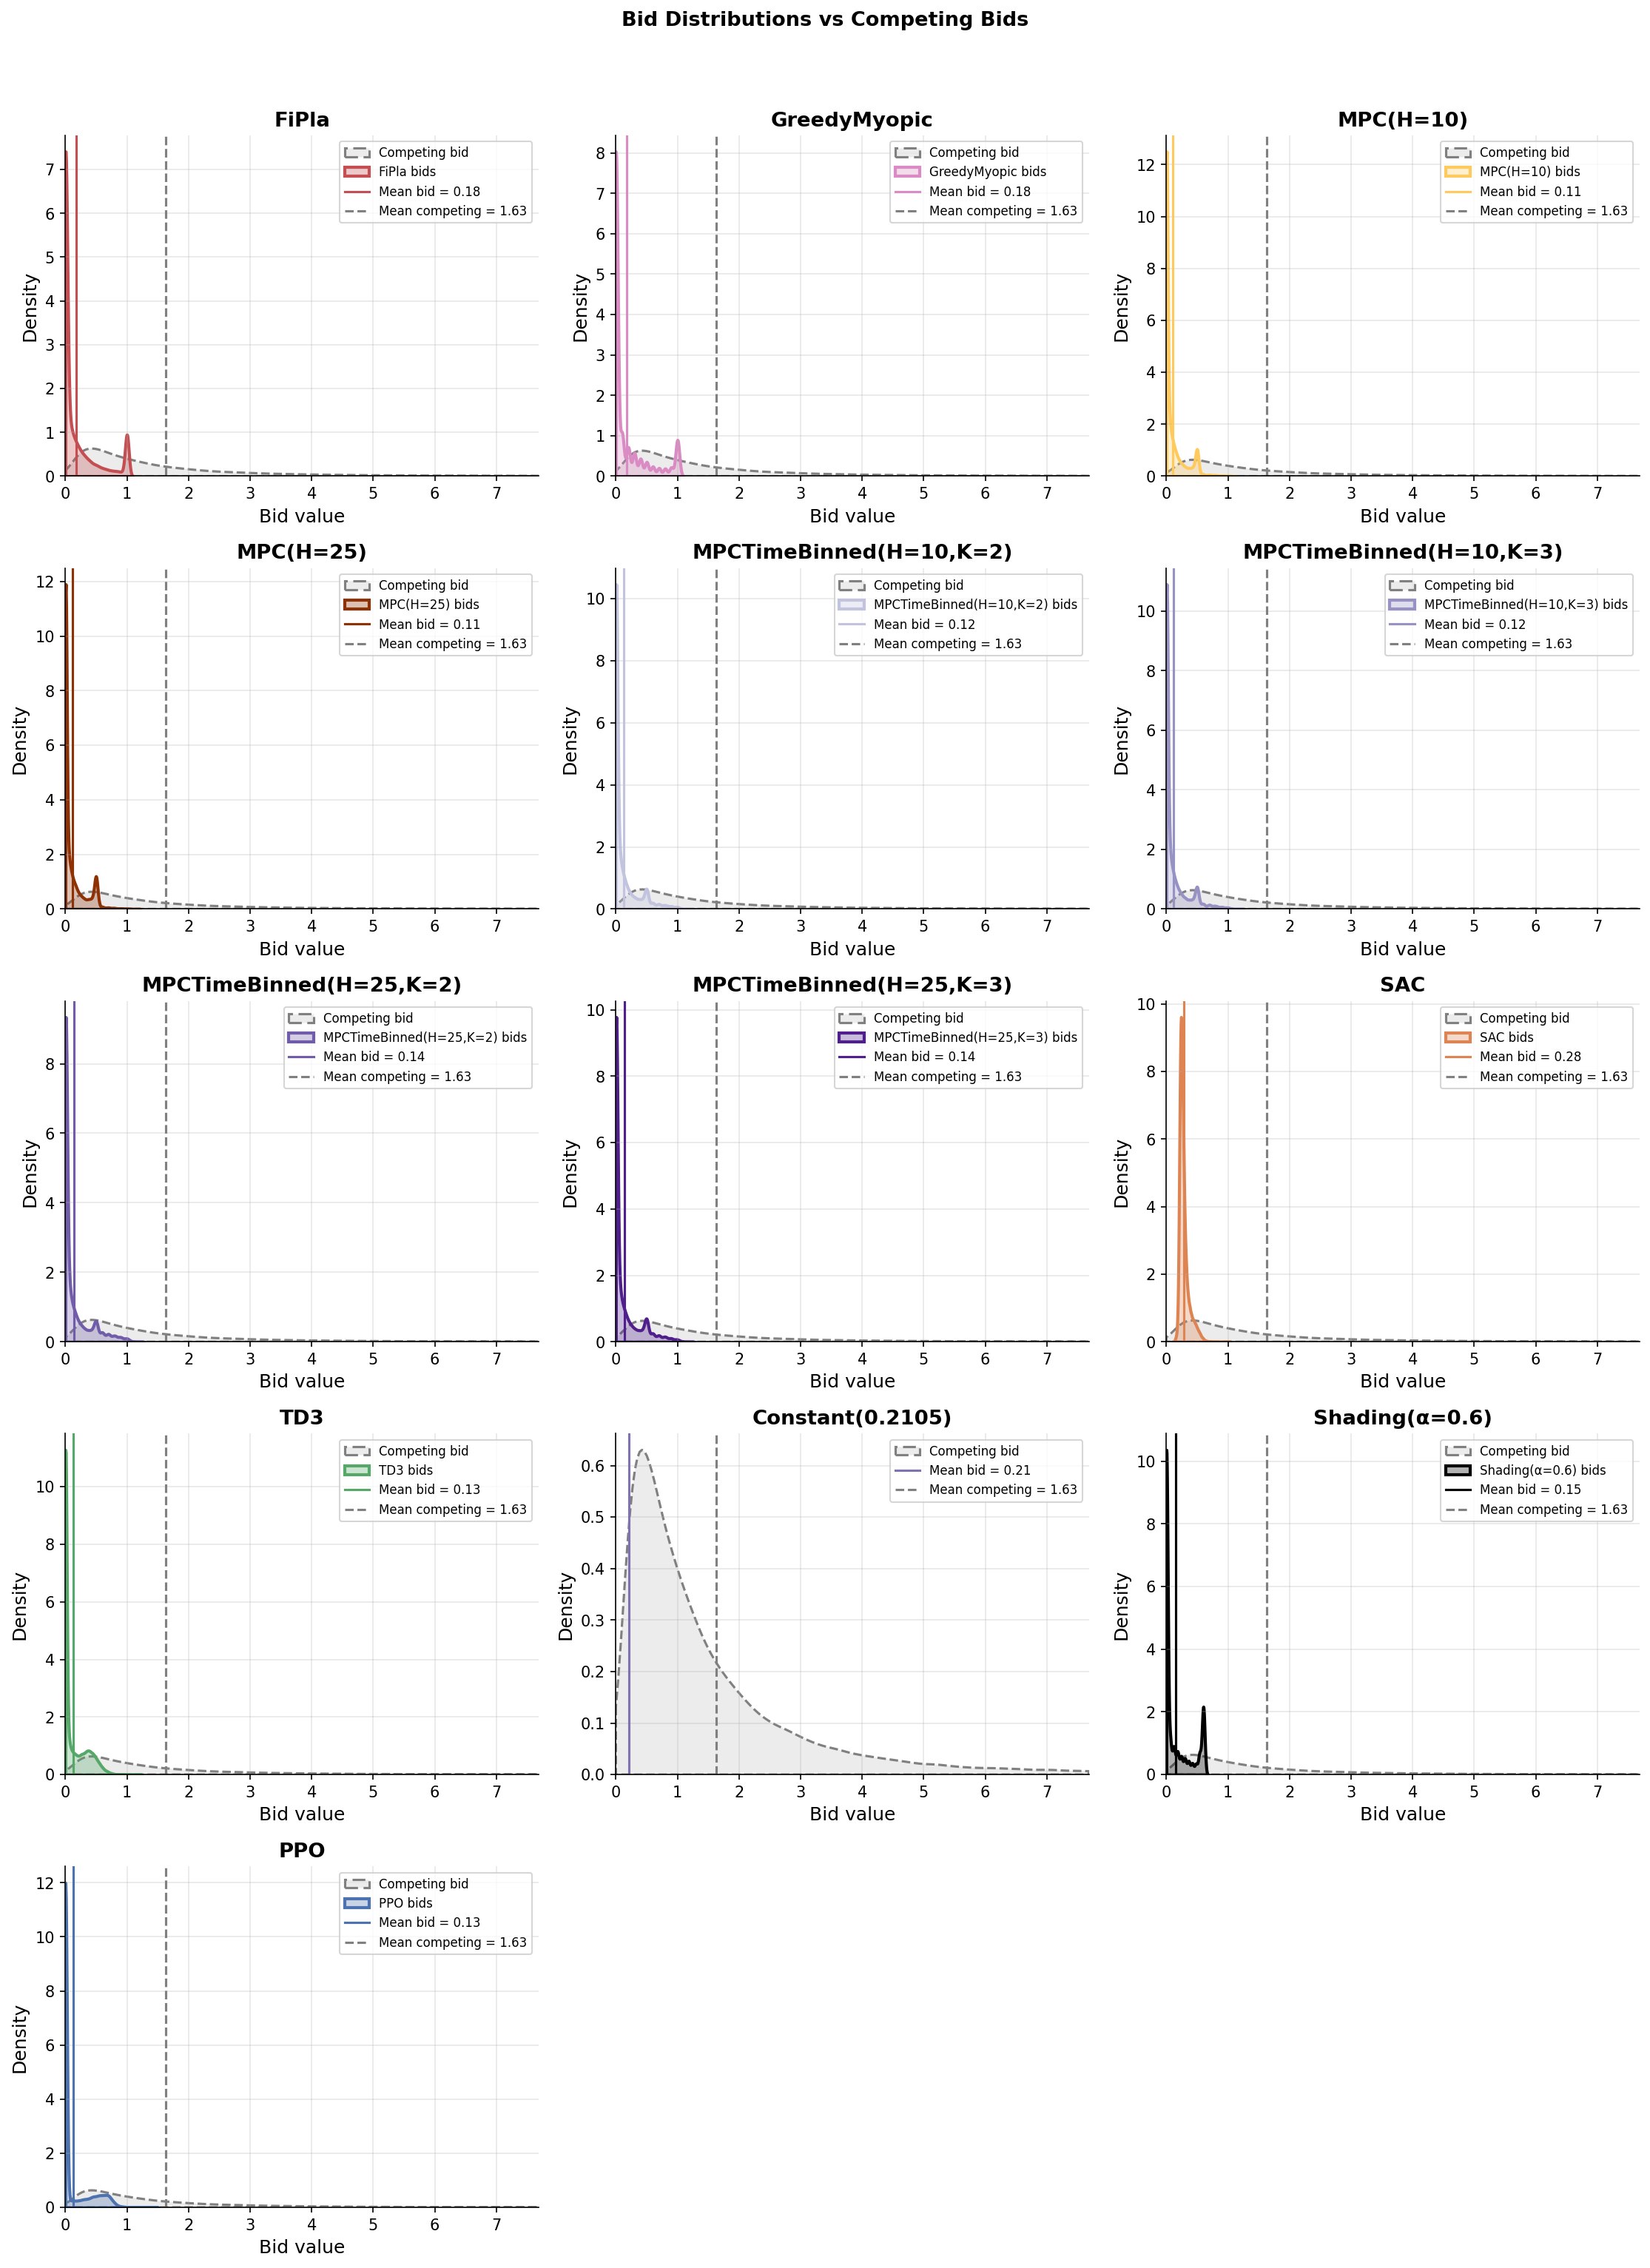

In [48]:
_ = plots.plot_bid_distributions(df_eta100, filename="bid_distributions_eta100.pdf")

#### Sigmoid :

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:611: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(bids, ax=ax, color=color, lw=2,


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/bid_distributions_eta50_sigmoid.pdf


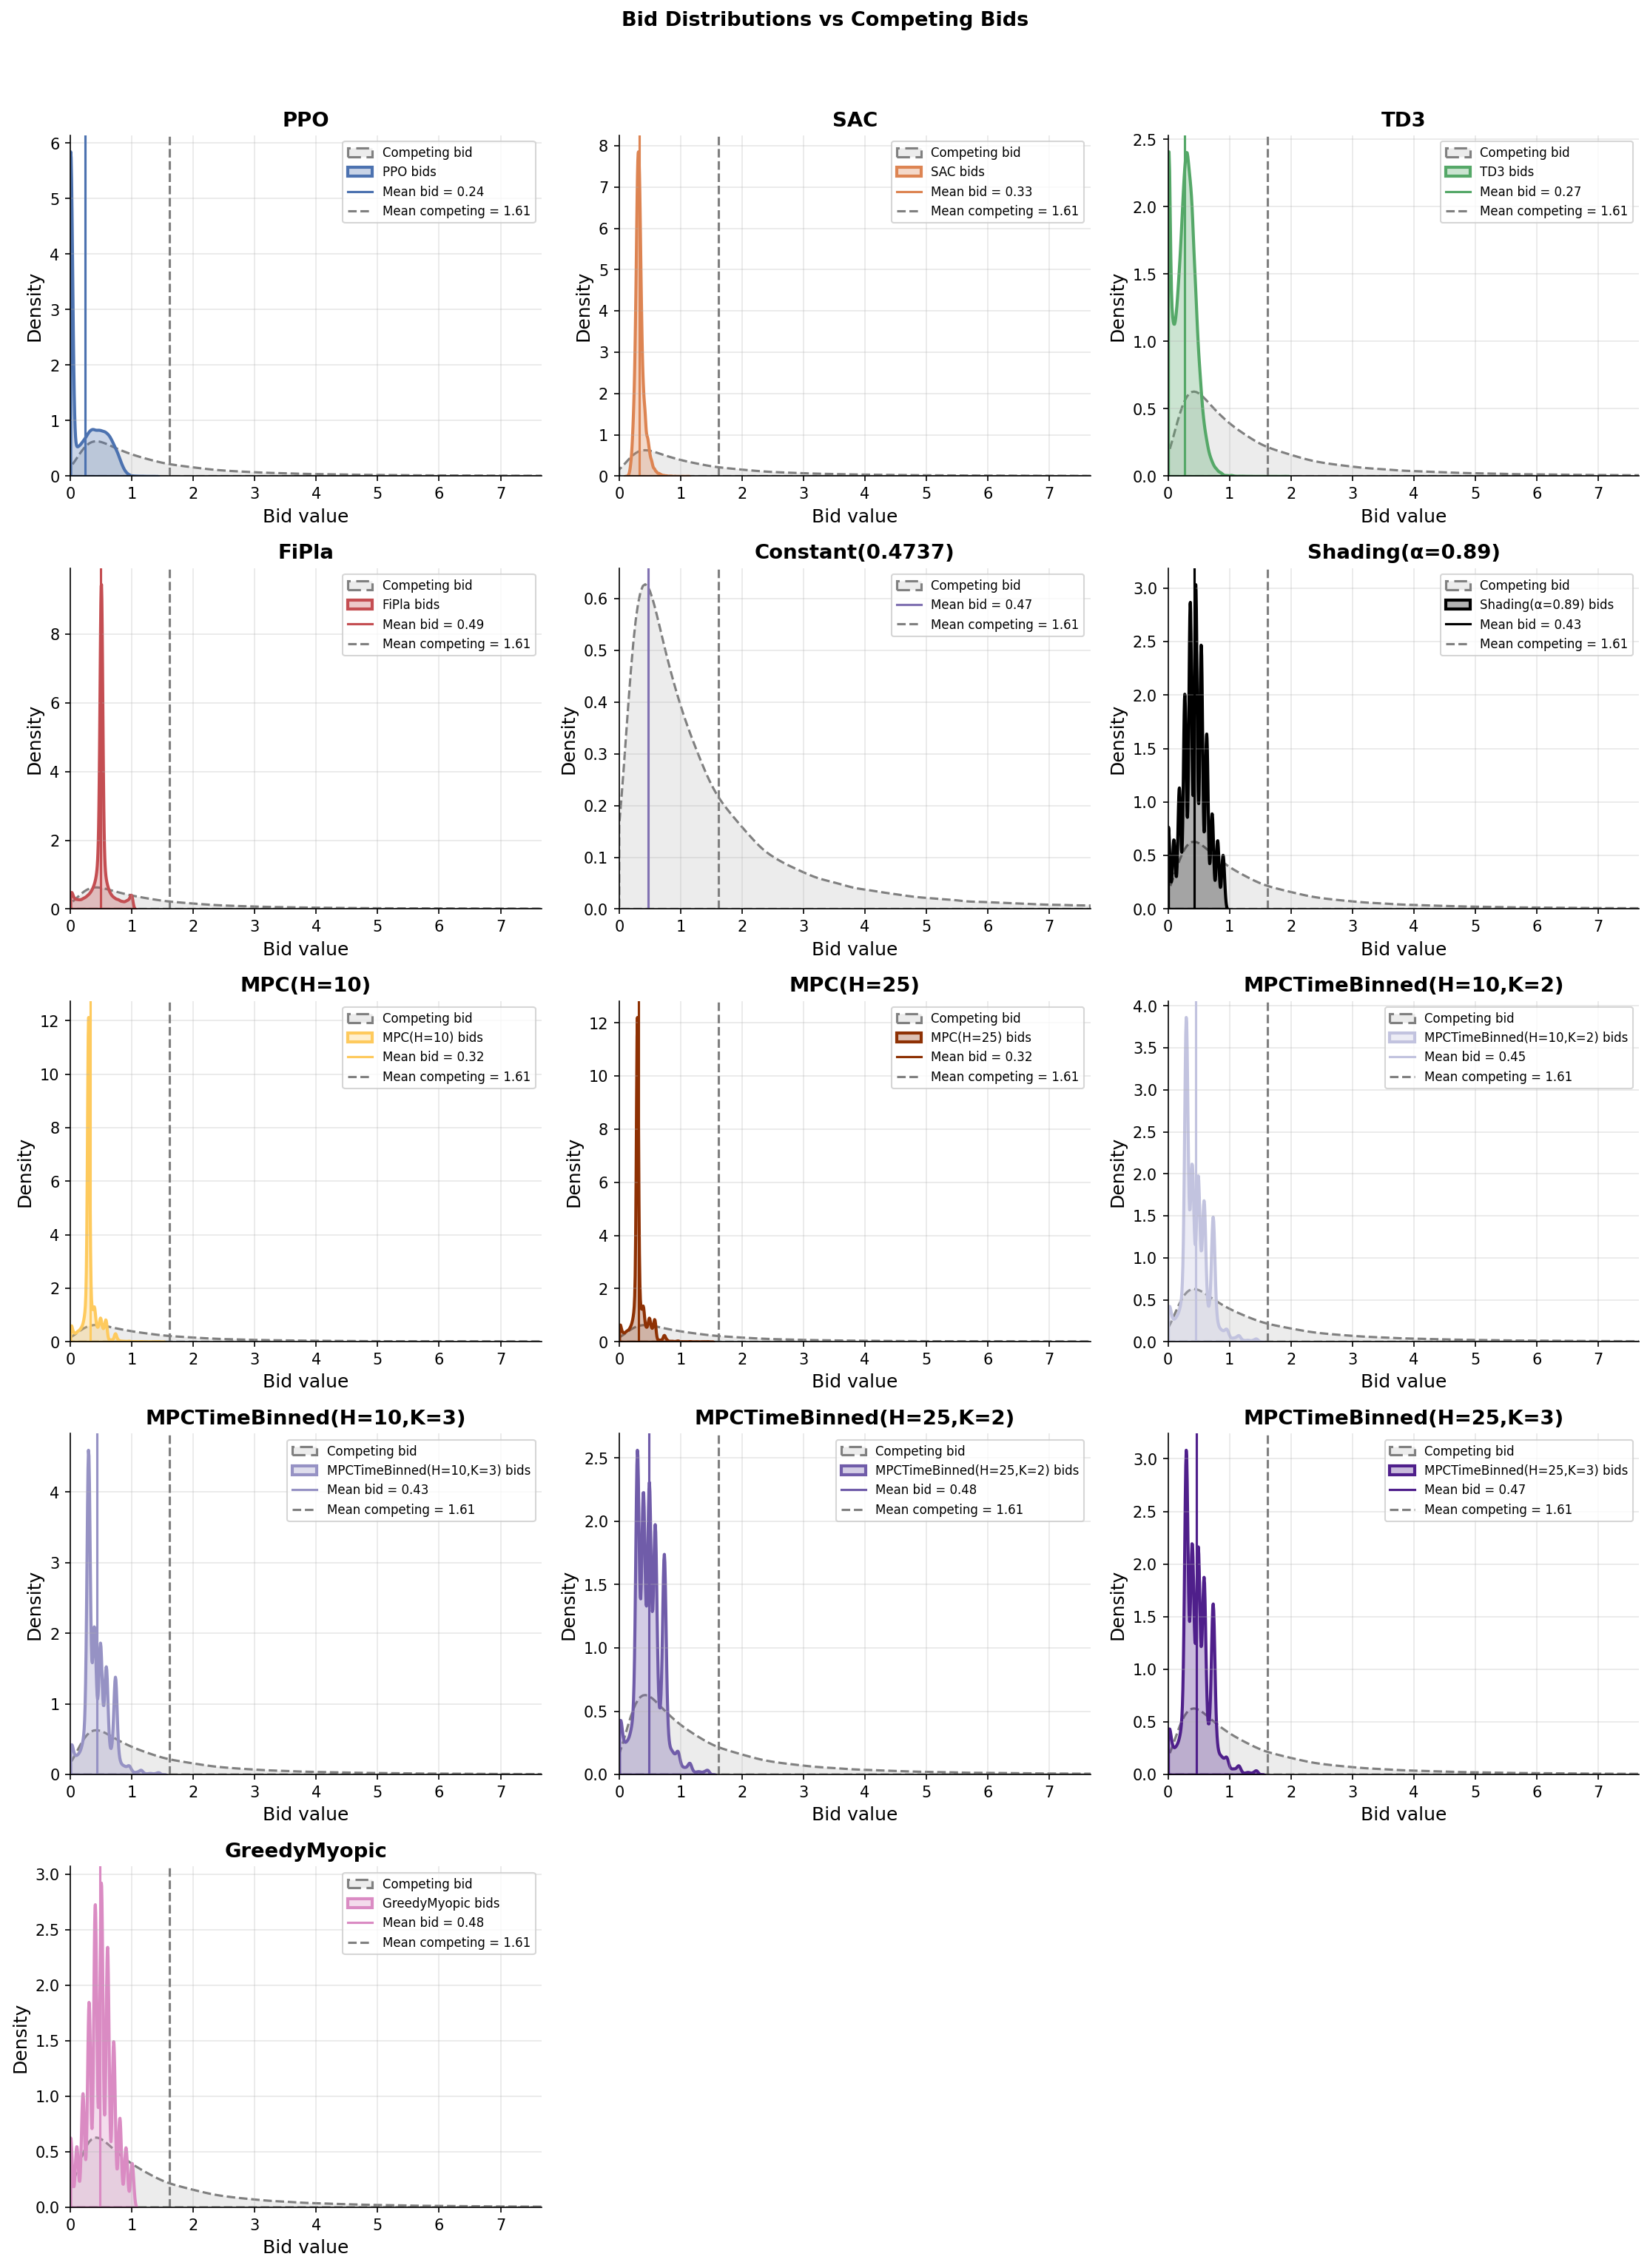

In [49]:
_ = plots.plot_bid_distributions(df_eta50_sigmoid, filename="bid_distributions_eta50_sigmoid.pdf")

### Win rate

Fraction of auctions won per policy, averaged over seeds. Under second-price rules the truthful bid (FiPla) is optimal, so its win rate serves as the upper reference.

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:653: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",


/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:660: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/win_rate_eta50.pdf


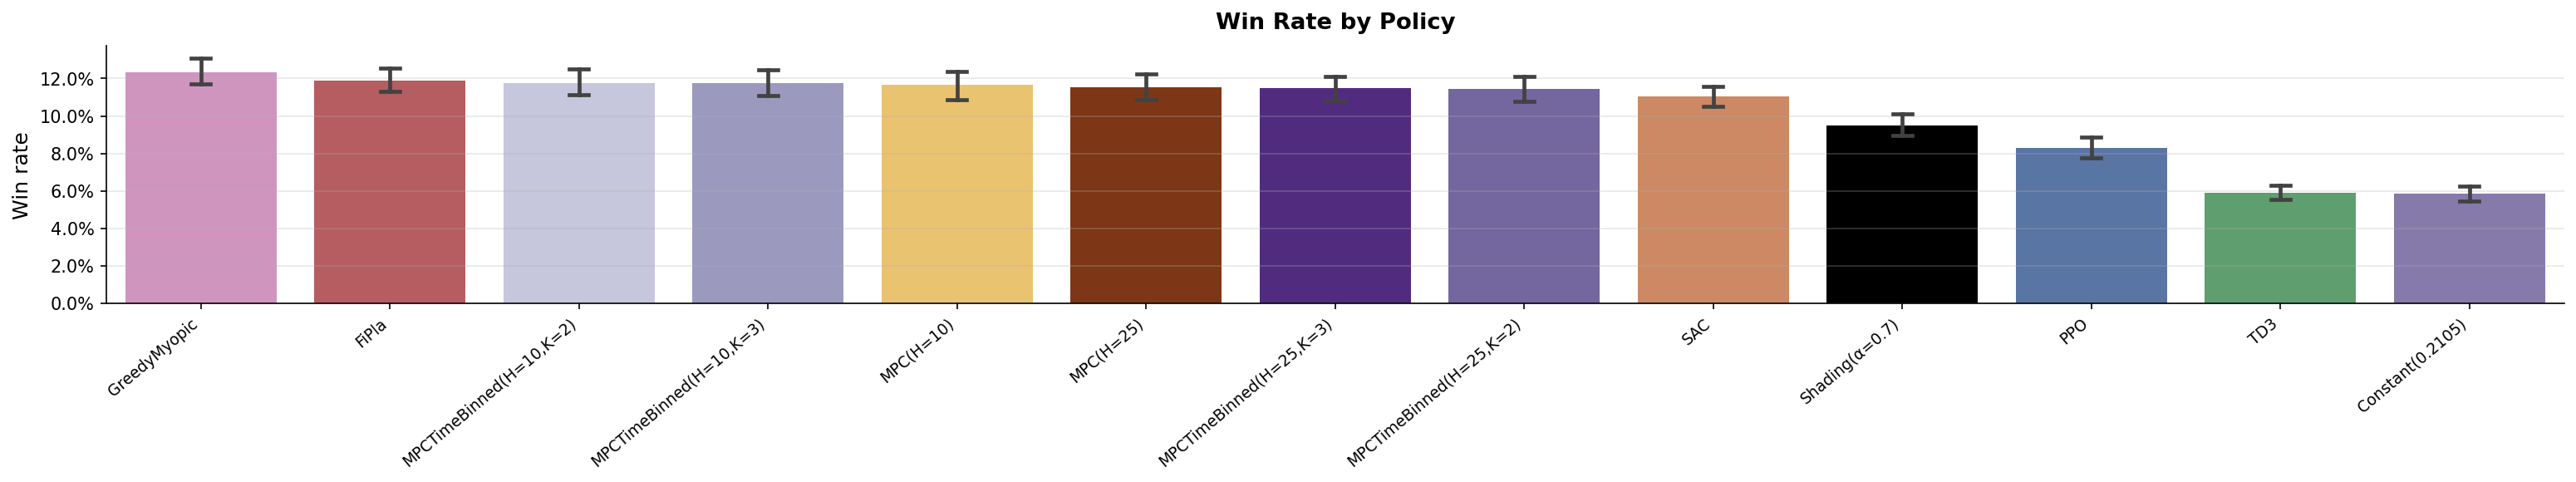

In [50]:
_ = plots.plot_win_rate(df_eta50, filename="win_rate_eta50.pdf")

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:653: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",


/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:660: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/win_rate_eta100.pdf


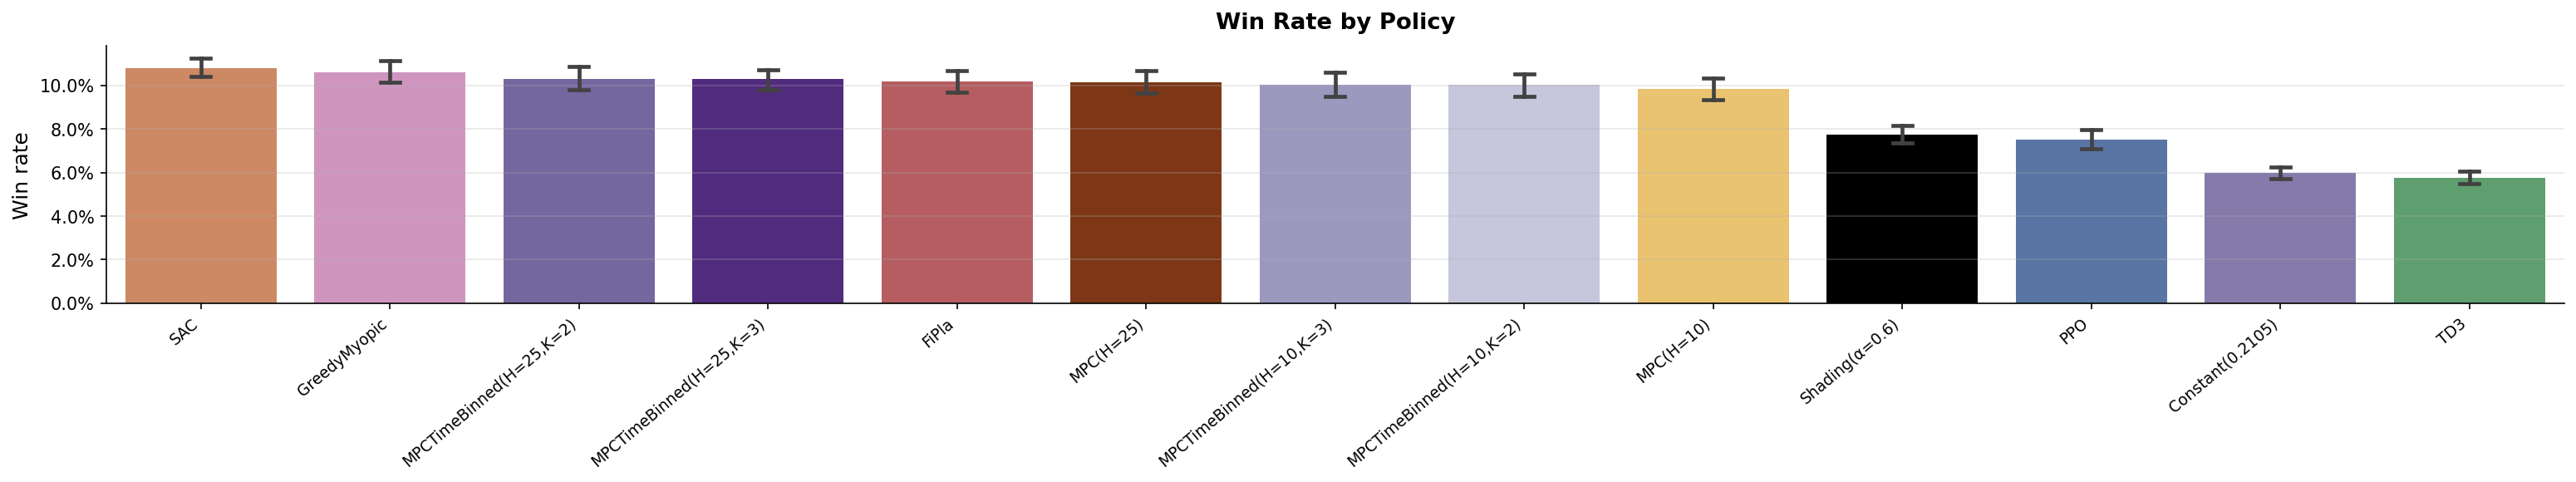

In [51]:
_ = plots.plot_win_rate(df_eta100, filename="win_rate_eta100.pdf")

#### Sigmoid :

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:653: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",


/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:660: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/win_rate_eta50_sigmoid.pdf


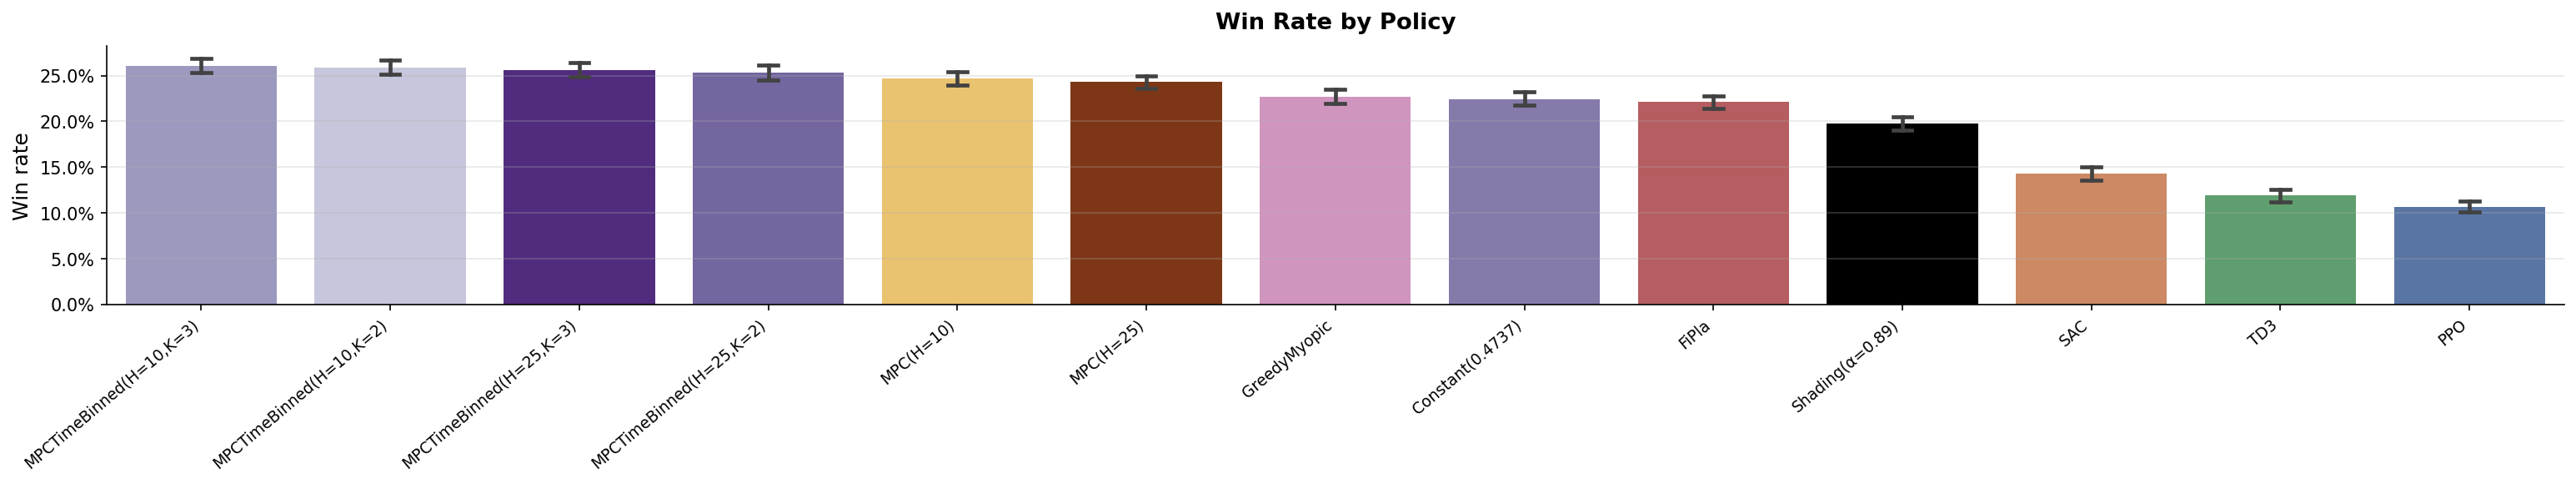

In [52]:
_ = plots.plot_win_rate(df_eta50_sigmoid, filename="win_rate_eta50_sigmoid.pdf")

### MPC's optimal alphas

At each auction step, MPC-family policies select the shading multiplier α* that maximises the estimated planning return over a rolling horizon. The distribution below shows which α* values are preferred across all steps and seeds, a concentration near high α values indicates the policy tends to bid aggressively, while a spread across the candidate set suggests the optimal multiplier is context-dependent.

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:823: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=mpc_df, x="policy", y="alpha_chosen",


/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:837: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/mpc_alpha_chosen_eta50.pdf


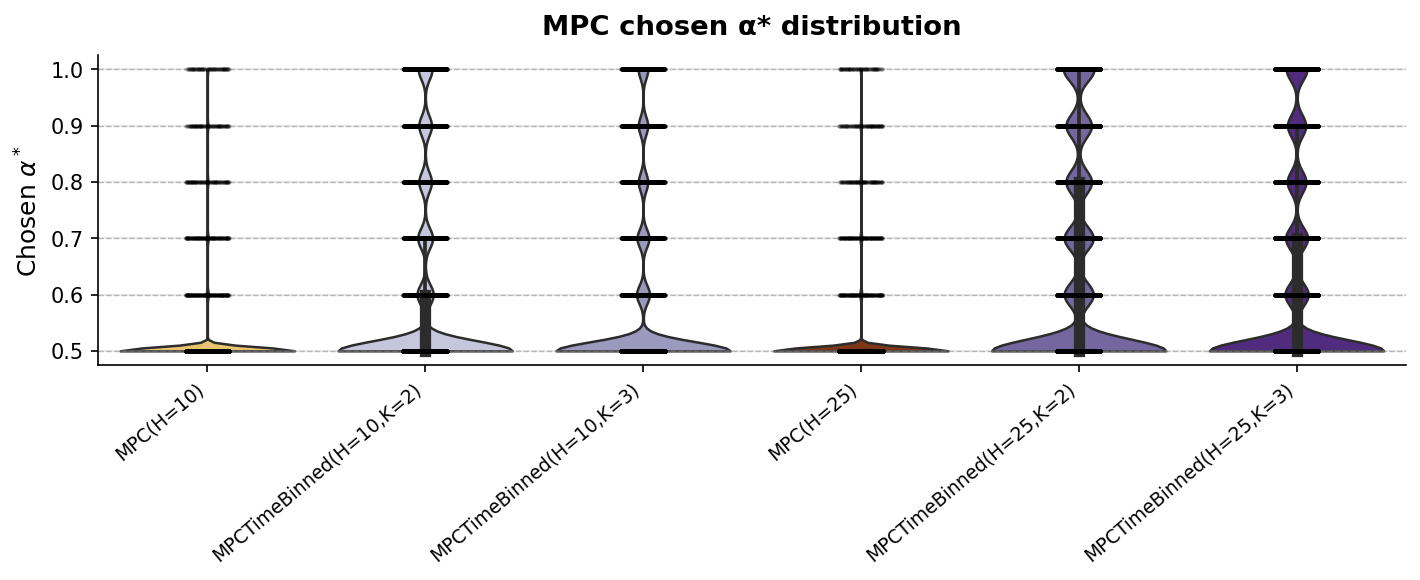

In [53]:
_ = plots.plot_mpc_alpha_chosen(df_eta50, filename="mpc_alpha_chosen_eta50.pdf")

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:823: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=mpc_df, x="policy", y="alpha_chosen",


/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:837: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/mpc_alpha_chosen_eta100.pdf


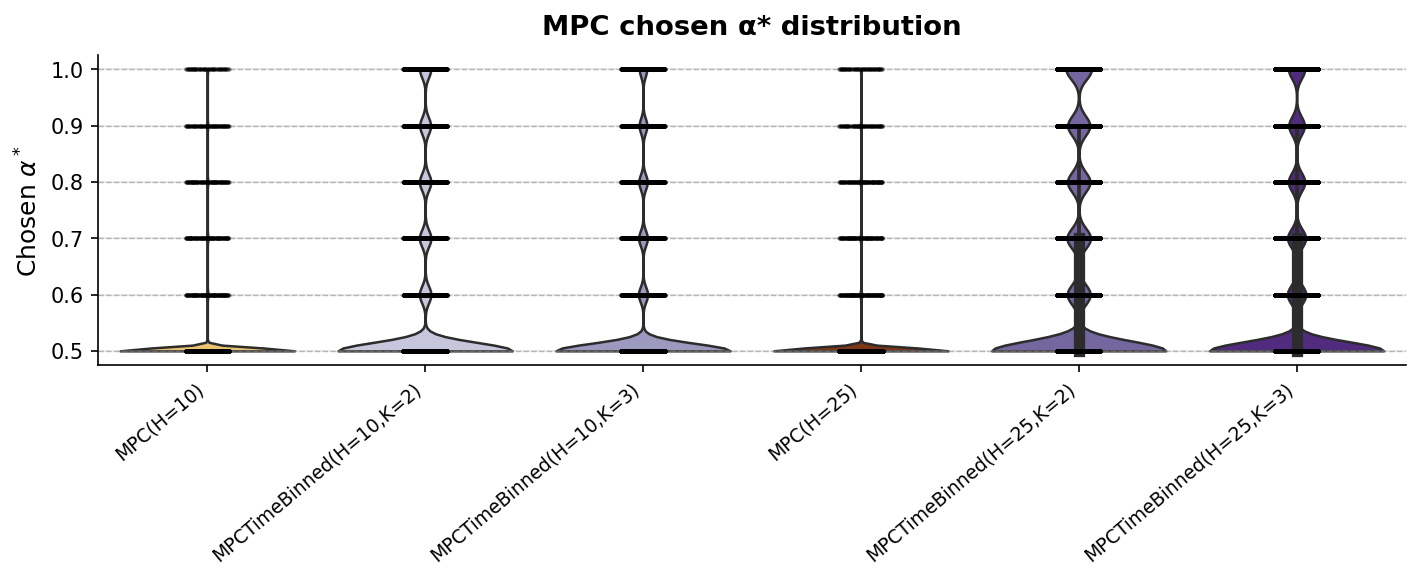

In [54]:
_ = plots.plot_mpc_alpha_chosen(df_eta100, filename="mpc_alpha_chosen_eta100.pdf")

#### Sigmoid :

/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:823: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=mpc_df, x="policy", y="alpha_chosen",


/home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots.py:837: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/mpc_alpha_chosen_eta50_sigmoid.pdf


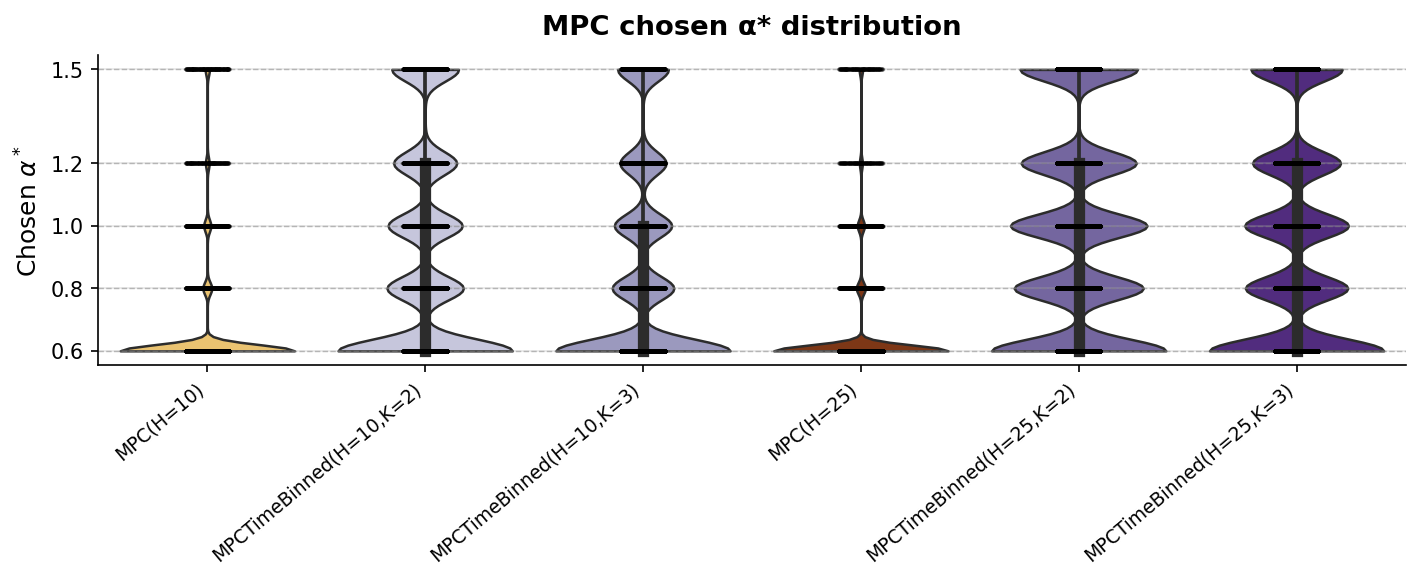

In [55]:
_ = plots.plot_mpc_alpha_chosen(df_eta50_sigmoid, filename="mpc_alpha_chosen_eta50_sigmoid.pdf")

### MPC chosen α* over normalised campaign time

Because campaign horizons are exponentially distributed (different length per seed), time is normalised to [0, 1] for each run before averaging. The curves show how the preferred shading multiplier evolves from the start to the end of a campaign.

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/mpc_alpha_over_time_eta50.pdf


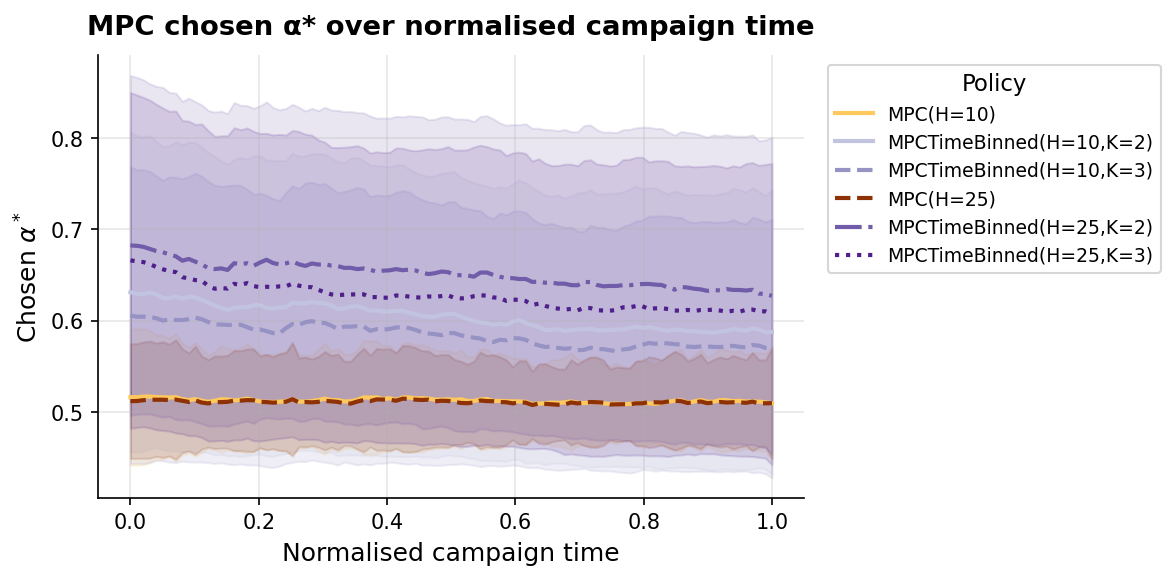

In [56]:
_ = plots.plot_alpha_over_normalized_time(df_eta50, filename="mpc_alpha_over_time_eta50.pdf")

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/mpc_alpha_over_time_eta100.pdf


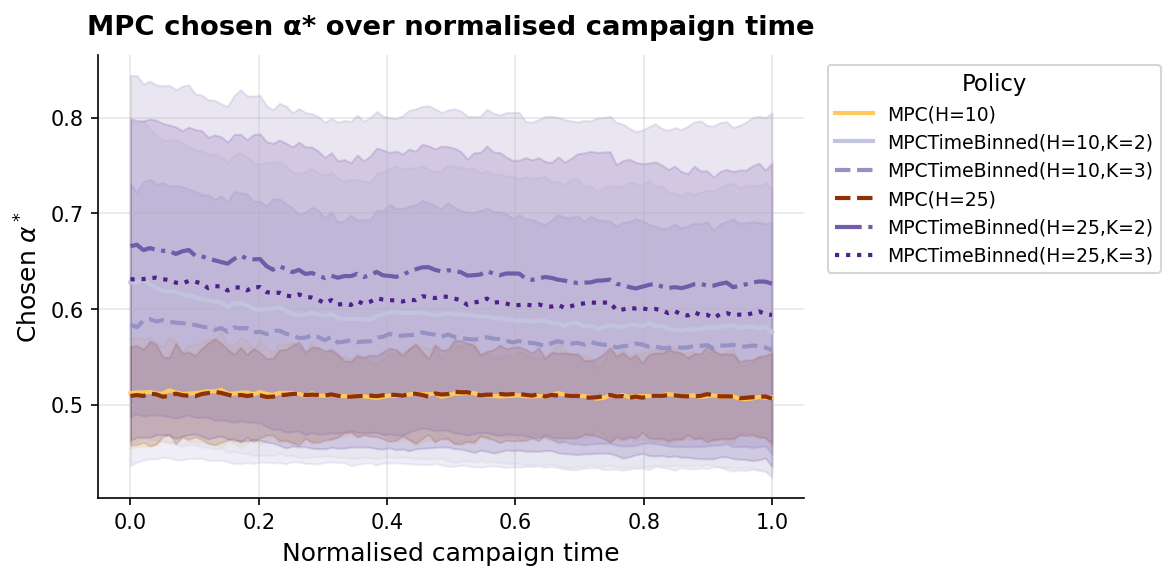

In [57]:
_ = plots.plot_alpha_over_normalized_time(df_eta100, filename="mpc_alpha_over_time_eta100.pdf")

#### Sigmoid :

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/mpc_alpha_over_time_eta50_sigmoid.pdf


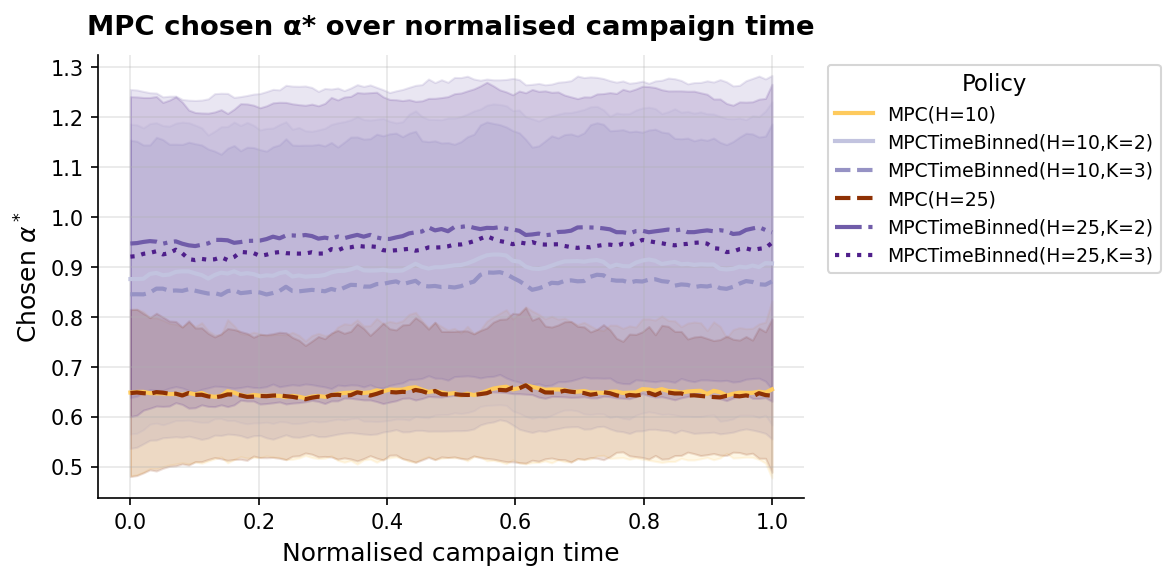

In [58]:
_ = plots.plot_alpha_over_normalized_time(df_eta50_sigmoid, filename="mpc_alpha_over_time_eta50_sigmoid.pdf")